# Projekt 1 – model scoringowy/ratingowy: przygotowanie danych (wymagania 3.1 i 3.2)

Notebook obejmuje definicję problemu, podział danych i schemat walidacji, kontrolę data leakage, jakość danych, EDA oraz przygotowanie cech dla modelu interpretowalnego (karta WoE + regresja logistyczna) i modelu black-box.

**Zasady**
1. Zbiór testowy jest tylko wydzielany i zapisywany – nie jest używany w EDA, przy dopasowaniu transformacji ani w CV.
2. Transformacje z parametrami wyznaczanymi z danych (kwantyle, mediany, granice binów, WoE, rzadkie kategorie, selekcja cech) są dopasowywane wyłącznie przez `.fit()` na zbiorze treningowym lub na foldzie treningowym.
3. Przed podziałem wykonywane są tylko operacje bezstanowe, liczone osobno dla każdego wiersza.
4. Konwencje: `default` = 1 oznacza default, PD = P(y = 1); WoE = ln(%dobrych / %złych) (Lab 1) – WoE > 0 oznacza niższe ryzyko, więc w regresji logistycznej na WoE oczekujemy β < 0.

## 0. Konfiguracja

Wszystkie progi i parametry są zdefiniowane w tej komórce i używane w dalszej części notebooka.

In [1]:
import os, sys, json, hashlib, platform, warnings, itertools
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import sklearn
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedGroupKFold, StratifiedKFold, train_test_split)
from matplotlib.patches import FancyArrowPatch, Rectangle

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# --- dane i cel --- #
DATA_PATH = "zbiór_5.csv"
TARGET = "default"
TARGET_PD = 0.04          # tendencja centralna PD; NIE zastępuje DR w próbie

# --- podziały i walidacja --- #
RNG_SEED = 42
TEST_SIZE = 0.20          # udział testu w całości
VALID_SIZE = 0.25         # udział validation w części deweloperskiej (train+validation) -> 20% całości
N_FOLDS = 5               # Stratified K-fold (wymóg: min. 5 foldów)
N_REPEATS = 3             # powtórzenia CV w teście poprawności pipeline'u (rozdz. 9)

# --- polityka czyszczenia (FinancialCleaner) --- #
CLEAN = dict(
    max_missing=0.50,      # usuwamy cechę, gdy NaN (prawdziwe braki) >= 50% obserwacji train
    quasi_const=0.99,      # usuwamy cechę, gdy najczęstsza wartość >= 99% obserwacji z wartością
    winsor=(0.01, 0.99),   # capping black-box: kwantyle 1% i 99% wyznaczone na train
    indicator_min=0.02,    # wskaźnik braku / wartości specjalnej tworzymy od 2% udziału na train
)

# --- binning, WoE i selekcja (model interpretowalny); wartości jak w Lab 1 --- #
BIN = dict(
    max_bins=5,            # maks. liczba przedziałów regularnych (Lab 1: max_bins = 5)
    min_bin_frac=0.05,     # min. udział obserwacji w przedziale (Lab 1: min_share = 0.05)
    smoothing=0.5,         # wygładzanie +0,5 chroni przed log(0) (Lab 1)
    iv_min=0.02,           # IV < 0,02 -> cecha bezużyteczna (Siddiqi 2017, Lab 1)
    corr_max=0.70,         # z pary cech WoE o |r| >= 0,70 zostaje cecha o wyższym IV
    max_features=8,        # limit cech karty: ~107 defaultów / 9 parametrów ≈ 12 zdarzeń na parametr (reguła EPV ≥ 10)
)
MIN_CAT_SHARE = BIN["min_bin_frac"]  # kategoria rzadsza niż 5% train -> "INNE" (spójnie z binami liczbowymi)
IV_SUSPICIOUS = 0.50                 # IV > 0,5 -> "podejrzanie silna – sprawdź przeciek" (Lab 1)
AUC_ALARM = 0.75                     # jednowymiarowa siła AUC >= 0,75 -> sygnał do audytu (Lab 3, 1.4)

ART_DIR = Path("artifacts")
FIG_DIR = ART_DIR / "fig"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Zapisuje bieżący wykres do artifacts/fig/<name>.png (wszystkie wykresy w jednym katalogu)."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

assert Path(DATA_PATH).is_file(), f"Brak pliku: {DATA_PATH}. Ustaw DATA_PATH na poprawną ścieżkę."
assert 0 < TARGET_PD < 1
assert 0 < TEST_SIZE < 1 and 0 < VALID_SIZE < 1
assert isinstance(N_FOLDS, int) and N_FOLDS >= 5, "Wymóg projektu: co najmniej 5 foldów."
assert 0 < CLEAN["max_missing"] <= 1 and 0 < CLEAN["quasi_const"] <= 1
assert 0 <= CLEAN["winsor"][0] < CLEAN["winsor"][1] <= 1
assert BIN["max_bins"] >= 2 and 0 < BIN["min_bin_frac"] < 1 and 0 < BIN["corr_max"] <= 1

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)
print(f"Planowany podział: train {(1-TEST_SIZE)*(1-VALID_SIZE):.0%}, "
      f"validation {(1-TEST_SIZE)*VALID_SIZE:.0%}, test {TEST_SIZE:.0%}; CV: {N_FOLDS} foldów")

Python 3.14.0 | numpy 2.3.4 | pandas 2.3.3 | scikit-learn 1.7.2 | scipy 1.16.3 | matplotlib 3.10.7
Planowany podział: train 60%, validation 20%, test 20%; CV: 5 foldów


## 1. Definicja PD, moment decyzji i dostępność zmiennych

**Zdarzenie i horyzont.** `default` = 1 oznacza zdarzenie ryzyka w przyjętym horyzoncie obserwacji. Dane nie zawierają dat, więc długości horyzontu nie da się sprawdzić w danych – przyjmujemy definicję z opisu zmiennych.

**Moment decyzji.** Zakładamy, że ocena jest wykonywana po sporządzeniu sprawozdania finansowego. Do modelu mogą trafić tylko informacje dostępne w tym momencie.

**Charakter danych.** Zbiór jest przekrojowy – bez dat i bez identyfikatora podmiotu, dlatego:
* podział w czasie (out-of-time) nie jest możliwy – stosujemy losowy podział warstwowy po `default`;
* powtórzenia podmiotów można sprawdzić tylko pośrednio (rozdział 2.2).

O wykluczeniu cechy decyduje jej opis i moment dostępności. Wysokie AUC lub IV pojedynczej cechy jest sygnałem do sprawdzenia, a nie dowodem przecieku.

## 2. Wczytanie danych i kontrola wejścia

Kontrole opisowe na całym pliku: typy kolumn, target, duplikaty, braki. W tym rozdziale nie są wyznaczane parametry transformacji.

In [2]:
df_local = pd.read_csv(DATA_PATH)
assert not df_local.empty, "Dane są puste."
assert df_local.columns.is_unique, "Powtarzające się nazwy kolumn."
assert TARGET in df_local.columns, f"Brakuje targetu {TARGET!r}."
assert df_local.index.is_unique and not df_local.index.hasnans

print("Rozmiar danych:", df_local.shape)
print("Typy kolumn:", df_local.dtypes.astype(str).value_counts().to_dict())
display(df_local.head(5))

NUM_COLS_df = df_local.select_dtypes(include="number").columns.tolist()
CAT_COLS_df = df_local.select_dtypes(exclude="number").columns.tolist()
print("Kolumny liczbowe:", len(NUM_COLS_df), "| kategoryczne/tekstowe:", len(CAT_COLS_df), CAT_COLS_df)

Rozmiar danych: (3000, 223)
Typy kolumn: {'float64': 216, 'int64': 5, 'object': 2}


,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,Wartosc_firmy,Rzeczowe_aktywa_trwale,Srodki_trwale,Naleznosci_dlugoterminowe,Inwestycje_dlugoterminowe,Rozliczenia_miedzyokresowe_dlugie,Aktywa_obrotowe,Zapasy,Naleznosci_krotkoterminowe,Naleznosci_dostaw_uslug_12m_powiazane,...,wsk_obrotowosc_gotowkowa,wsk_struktura_majatku,wsk_struktury_kapitalu,wsk_zast_kapitalu_wlasnego,wsk_zast_kapitalu_podstawowego,wsk_zast_kapitalu_stalego,wsk_zast_kapitalu_obcego,wsk_sytuacji_fin,wsk_struktura_kap_wlasnego_1,wsk_struktura_kap_wlasnego_2,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,214,2229,-0.0022,0.3131,0.3027,2321,"142,410.7200","103,108.8800",0.0000,0.0000,"52,566.7000","52,566.7000",0.0000,"50,542.1800",0.0000,"39,301.8400",0.0000,"29,040.5000",0.0000,...,35.3946,2.6235,0.1791,0.2098,0.8729,0.6091,3.0730,0.0683,0.1519,0.1519,0.1519,0.1637,5.5821,0.2891,0.2891,0.2891,0.8481,0.7760,-2.0730,1
1,117,214,2849,-0.0064,0.2593,0.1935,2066,"5,000.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"5,000.0000",0.0000,0.0000,0.0000,...,0.0000,0.0000,50.0000,50.0000,50.0000,50.0000,0.0000,0.5000,1.0000,1.0000,1.0000,inf,0.0000,0.0000,0.0000,0.0000,0.0000,-1.0000,1.0000,1
2,117,214,4120,0.0227,0.2751,0.2624,3166,"13,126.2600",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"12,126.2600",0.0000,"12,121.8300",0.0000,...,0.0000,0.0000,131.2626,131.2626,50.0000,131.2626,0.0000,1.3126,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0825,1
3,117,214,4690,-0.0046,0.1158,0.3007,1951,"1,219,468.1600","242,162.8900",0.0000,0.0000,"238,162.8900",0.0000,0.0000,"4,000.0000",0.0000,"977,305.2700","6,358.5800","811,441.2800",0.0000,...,55.0211,0.2478,0.2062,0.8608,0.8259,1.3456,1.0345,0.8321,0.1709,0.1709,0.1709,0.1735,4.8500,0.0963,0.1529,0.1529,0.8291,0.8143,-0.0345,1
4,117,216,6201,0.1172,0.3968,0.2840,2755,"274,553.2200",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"274,553.2200",0.0000,"146,340.7000",0.0000,...,4.3483,0.0000,81.8690,"2,712.4012",50.0000,"2,712.4012",0.0121,0.8187,0.9879,0.9879,0.9879,1.8535,0.0122,0.0000,0.0000,0.0000,0.0121,-0.4549,0.9879,1


Kolumny liczbowe: 221 | kategoryczne/tekstowe: 2 ['schemat_wsk_bilans', 'schemat_wsk_rzis']


### 2.1. Kolumny kodowe i poprawność targetu

`pkdKod`, `formaWlasnosci_Symbol` i `szczegolnaFormaPrawna_Symbol` są zapisane jako liczby, ale są kodami (zmiennymi kategorycznymi). Sprawdzamy liczbę ich poziomów oraz to, czy target jest binarny i kompletny.

In [3]:
CODES = ["pkdKod", "formaWlasnosci_Symbol", "szczegolnaFormaPrawna_Symbol"]
missing_codes = sorted(set(CODES) - set(df_local.columns))
assert not missing_codes, f"Brakujące kolumny kodowe: {missing_codes}"
for col in CODES:
    print(f"\n{col} | liczba unikalnych wartości: {df_local[col].nunique(dropna=True)} | braki: {df_local[col].isna().sum()}")
    display(df_local[col].value_counts(dropna=False).head(12).to_frame("liczebność"))

# Walidacja PRZED konwersją: astype(int) mogłoby ukryć niepożądane wartości.
y_candidate = pd.to_numeric(df_local[TARGET], errors="coerce")
assert y_candidate.notna().all(), "Target zawiera NaN lub wartości nienumeryczne."
assert y_candidate.isin([0, 1]).all(), "Target nie jest binarny 0/1."

X_raw = df_local.drop(columns=[TARGET]).copy()
y_raw = y_candidate.astype("int64").rename(TARGET)
assert TARGET not in X_raw.columns
assert X_raw.index.equals(y_raw.index) and len(X_raw) == len(y_raw)
assert y_raw.nunique() == 2, "Do stratyfikacji i AUC potrzebne są obie klasy."

display(pd.DataFrame({"liczba": y_raw.value_counts().sort_index(),
                      "udział (%)": (100 * y_raw.value_counts(normalize=True).sort_index()).round(2)}))
print(f"Default rate (DR) próby = {y_raw.mean():.2%} ({int(y_raw.sum())} defaultów); "
      f"kotwica PD (cel kalibracji) = {TARGET_PD:.2%}")


pkdKod | liczba unikalnych wartości: 378 | braki: 0


,liczebność
pkdKod,
6820,132
7022,105
4120,105
6201,101
4110,98
6920,95
4941,72
4690,67
6810,64



formaWlasnosci_Symbol | liczba unikalnych wartości: 18 | braki: 0


,liczebność
formaWlasnosci_Symbol,
214,2008
215,293
216,239
0,160
224,78
226,61
225,61
113,38
227,37



szczegolnaFormaPrawna_Symbol | liczba unikalnych wartości: 1 | braki: 0


,liczebność
szczegolnaFormaPrawna_Symbol,
117,3000


,liczba,udział (%)
default,,
0,2822,94.0700
1,178,5.9300


Default rate (DR) próby = 5.93% (178 defaultów); kotwica PD (cel kalibracji) = 4.00%


`szczegolnaFormaPrawna_Symbol` ma jeden poziom i nie trafia do modeli. DR próby (5,93%) jest wyższy niż docelowe PD = 4% – różnicę koryguje kalibracja poziomu PD na zbiorze validation (osobny notebook), a nie zmiana danych uczących.

### 2.2. Duplikaty i powtarzające się podmioty

Plik nie zawiera identyfikatora firmy. Sprawdzamy identyczne wiersze oraz identyczne odciski obserwacji (`pkdKod`, `formaWlasnosci_Symbol`, `wsk_liczba_dni_istnienia`, `Aktywa`). Powtórzony odcisk oznaczałby, że ta sama obserwacja występuje w pliku więcej niż raz.

In [4]:
print("W pełni identyczne obserwacje (łącznie z targetem):", int(df_local.duplicated().sum()))
print("W pełni identyczne obserwacje (z wyłączeniem targetu):", int(X_raw.duplicated().sum()))

FINGERPRINT = ["pkdKod", "formaWlasnosci_Symbol", "wsk_liczba_dni_istnienia", "Aktywa"]
assert set(FINGERPRINT).issubset(X_raw.columns), (
    f"Brakuje pól do fingerprintu: {set(FINGERPRINT) - set(X_raw.columns)}")
fp = pd.util.hash_pandas_object(X_raw[FINGERPRINT], index=False)
fp.name = "fingerprint"
assert fp.index.equals(X_raw.index)

dup_fp = fp.duplicated(keep=False)
GROUPS = fp.copy() if dup_fp.any() else None
print("Wiersze z powtórzonym odciskiem:", int(dup_fp.sum()))
print("Unikalne odciski:", fp.nunique())
print("Podział grupowy:", "tak" if GROUPS is not None else "nie")
if GROUPS is not None:
    print("Największe liczebności grup:")
    display(fp.value_counts().head(10).to_frame("liczebnosc"))
    warnings.warn("Fingerprint nie jest identyfikatorem podmiotu. Zweryfikuj, czy grupowanie jest uzasadnione.")

W pełni identyczne obserwacje (łącznie z targetem): 0
W pełni identyczne obserwacje (z wyłączeniem targetu): 0
Wiersze z powtórzonym odciskiem: 0
Unikalne odciski: 3000
Podział grupowy: nie


**Wniosek.** Brak identycznych wierszy i powtórzonych odcisków, więc w rozdziale 4 stosujemy podział warstwowy bez grup. Kontrola wykrywa tylko identyczne zapisy – bez identyfikatora podmiotu nie da się wykluczyć, że ta sama firma występuje z danymi z różnych lat.

### 2.3. Zduplikowane kolumny

Kolumny o identycznych wartościach są tu tylko raportowane; usuwa je `FinancialCleaner` w `fit()` na zbiorze treningowym.

In [5]:
DUPLICATES = X_raw.columns[X_raw.T.duplicated()].tolist()
cechy_zduplikowane = []
for i, col in enumerate(X_raw.columns):
    for prev_col in X_raw.columns[:i]:
        if X_raw[col].equals(X_raw[prev_col]):
            cechy_zduplikowane.append(prev_col)
            break
assert len(cechy_zduplikowane) == len(DUPLICATES)
assert all(X_raw[a].equals(X_raw[b]) for a, b in zip(DUPLICATES, cechy_zduplikowane))
print("Dokładnie zduplikowane kolumny:", len(DUPLICATES))
display(pd.DataFrame({"duplikat": DUPLICATES, "odpowiada kolumnie": cechy_zduplikowane}))

Dokładnie zduplikowane kolumny: 8


,duplikat,odpowiada kolumnie
0,wsk_rent_sprzedazy,wsk_ROS
1,wsk_zysk_operacyjny_zob_1,wsk_zysk_op_zobowiazania
2,wsk_zadluzenie_gotowka,wsk_koszty_odsetki_przychody
3,wsk_ebitda_zobowiazan_odsetki_1,wsk_ebitda_koszty_odsetkowe_1
4,wsk_ebitda_zobowiazan_odsetki_2,wsk_ebitda_koszty_odsetkowe_2
5,wsk_poziom_kosztow_operacyjnych,wsk_koszty_przychody
6,wsk_poziom_kosztow_finansowych,wsk_koszty_fin_przychody
7,wsk_struktura_kap_wlasnego_1,wsk_udzial_kap_wlasnego_aktywa_1


### 2.4. Braki, wartości nieskończone i dominacja zer

Przegląd całego pliku. Rozróżniamy `NaN` (brak wartości) i `±inf` (dzielenie przez zero we wskaźnikach). Ich znaczenie sprawdzamy na zbiorze treningowym w rozdziale 6.2.

In [6]:
X_num = X_raw.select_dtypes(include="number").astype(float)
nan_cnt = X_num.isna().sum()
posinf_cnt = pd.Series(np.isposinf(X_num.to_numpy()).sum(axis=0), index=X_num.columns)
neginf_cnt = pd.Series(np.isneginf(X_num.to_numpy()).sum(axis=0), index=X_num.columns)
przeglad = pd.DataFrame({"NaN": nan_cnt, "+inf": posinf_cnt, "-inf": neginf_cnt})
przeglad["NaN (%)"] = 100 * przeglad["NaN"] / len(X_raw)
przeglad["inf (%)"] = 100 * (przeglad["+inf"] + przeglad["-inf"]) / len(X_raw)
print(f"NaN łącznie: {int(nan_cnt.sum())} | +inf: {int(posinf_cnt.sum())} | -inf: {int(neginf_cnt.sum())}")
print("Kolumny z NaN lub inf:")
display(przeglad[(przeglad["NaN"] > 0) | (przeglad["+inf"] + przeglad["-inf"] > 0)]
        .sort_values(["NaN (%)", "inf (%)"], ascending=False).round(2))

X_num_finite = X_num.replace([np.inf, -np.inf], np.nan)
niebrakujace = X_num_finite.notna().sum()
liczba_zer = (X_num_finite == 0).sum()
udzial_zer = liczba_zer.div(niebrakujace.replace(0, np.nan))
duzo_zer = pd.DataFrame({
    "niebrakujące": niebrakujace,
    "zera": liczba_zer,
    "udział zer": udzial_zer,
    "unikalne": X_num_finite.nunique(dropna=True),
})
duzo_zer = duzo_zer[duzo_zer["udział zer"] > 0.90].sort_values("udział zer", ascending=False)
print("Cechy numeryczne z >90% zer wśród wartości dostępnych:", len(duzo_zer))
display(duzo_zer.round(4))

NaN łącznie: 20854 | +inf: 1005 | -inf: 0
Kolumny z NaN lub inf:


,NaN,+inf,-inf,NaN (%),inf (%)
RP_przeplywy_operacyjne,2966,0,0,98.8700,0.0000
wsk_akt_generowania_got_2,2966,0,0,98.8700,0.0000
wsk_pokrycie_wyd_fin_gotowkowe_2,2966,0,0,98.8700,0.0000
wsk_pokrycie_zob_kr_gotowkowe_2,2966,0,0,98.8700,0.0000
wsk_zadluzenia_gotowki_2,2966,0,0,98.8700,0.0000
wsk_zysk_CF_operacyjny,2966,0,0,98.8700,0.0000
RP_amortyzacja,2873,0,0,95.7700,0.0000
wsk_plynnosc_biez_1,101,901,0,3.3700,30.0300
wsk_struktura_kap_wlasnego_s_2,42,98,0,1.4000,3.2700
wsk_kapital_do_aktywa,42,6,0,1.4000,0.2000


Cechy numeryczne z >90% zer wśród wartości dostępnych: 33


,niebrakujące,zera,udział zer,unikalne
Naleznosci_dostaw_uslug_pow12m_kapitale,3000,2999,0.9997,2
Zobowiazania_dostaw_uslug_pow12m_kapitale,3000,2999,0.9997,2
Zobowiazania_dostaw_uslug_pow12m_powiazane,3000,2997,0.9990,4
Naleznosci_dostaw_uslug_pow12m_powiazane,3000,2995,0.9983,6
Ujemna_wartosc_firmy,3000,2994,0.9980,7
Pozostale_rezerwy,3000,2985,0.9950,16
Zobowiazania_dostaw_uslug_12m_kapitale,3000,2980,0.9933,21
Zobowiazania_dostaw_uslug_pow12m,3000,2974,0.9913,25
Wartosc_firmy,3000,2972,0.9907,29
Zobowiazania_dostaw_uslug_pow12m_pozostale,3000,2970,0.9900,31


## 3. Transformery danych

* **Transformacje bezstanowe** (`add_stateless_features`) – liczone osobno dla każdego wiersza, więc mogą być wykonane przed podziałem: dział PKD, `log1p` aktywów, `signed_log1p` pozycji kwotowych.
* **Transformacje z parametrami** – klasy zgodne z API scikit-learn; parametry są wyznaczane w `fit()` i stosowane w `transform()`:

| Klasa | Co wyznacza w `fit()` | Użycie |
|---|---|---|
| `FinancialCleaner` | cechy do usunięcia (braki, quasi-stałe, duplikaty), granice cappingu, wartości zastępujące `±inf`, mediany, średnie i odchylenia | obie ścieżki |
| `CategoryGrouper` | listę wystarczająco licznych kategorii; pozostałe → `INNE` | obie ścieżki |
| `WoEEncoder` | granice binów monotonicznych, WoE, IV, selekcję cech | model interpretowalny |
| `ScoringFeatureBuilder` | łączy powyższe w ścieżkę `mode="woe"` albo `mode="blackbox"` | obie ścieżki |

**Transformacje bezstanowe.**

In [7]:
def signed_log1p(x):
    """
    sign(x) * ln(1 + |x|): kompresuje skalę kwot, zachowuje znak i zero; inf pozostaje inf.
    """
    return np.sign(x) * np.log1p(np.abs(x))

def add_stateless_features(data, level_cols=()):
    """
    Cechy liczone wiersz po wierszu, bez żadnych statystyk z próby.
    """
    out = data.copy()
    pkd = pd.to_numeric(out["pkdKod"], errors="coerce")
    out["pkd_div"] = (pkd // 100).astype("Int64").astype("string").str.zfill(2).fillna("BRAK").astype(str)
    out["forma_wl"] = out["formaWlasnosci_Symbol"].astype("string").fillna("BRAK").astype(str)
    aktywa = pd.to_numeric(out["Aktywa"], errors="coerce")
    out["log_aktywa"] = np.log1p(aktywa.where(aktywa >= 0))      # ujemne aktywa -> NaN (wartość niemożliwa)
    nowe = {f"slog_{c}": signed_log1p(pd.to_numeric(out[c], errors="coerce")) for c in level_cols}
    return pd.concat([out, pd.DataFrame(nowe, index=out.index)], axis=1)

assert np.isclose(signed_log1p(-9), -np.log(10)) and np.isclose(signed_log1p(9), np.log(10))
assert signed_log1p(0) == 0

**`FinancialCleaner`** – czyszczenie cech liczbowych. W `fit()` wyznacza: cechy do usunięcia (braki ≥ `max_missing`, cechy quasi-stałe, duplikaty kolumn), granice cappingu i wartości zastępujące `±inf`, mediany do imputacji oraz średnie i odchylenia do standaryzacji. W trybie `inf_policy="keep"` (karta WoE) tylko usuwa cechy, a wartości specjalne obsługuje binning.

In [8]:
class FinancialCleaner(BaseEstimator, TransformerMixin):
    """
    Czyszczenie zmiennych liczbowych; wszystkie parametry wyznaczane w fit() na train.
    """

    def __init__(self, max_missing=0.50, quasi_const=0.99, winsor=(0.01, 0.99), impute=True,
                 indicator_min=0.02, scale=False, inf_policy="cap", drop_duplicates=True):
        self.max_missing = max_missing              # maks. udział NaN (inf to nie brak)
        self.quasi_const = quasi_const              # maks. udział najczęstszej wartości
        self.winsor = winsor                        # kwantyle cappingu (None = bez cappingu)
        self.impute = impute                        # imputacja medianą + flagi __isna
        self.indicator_min = indicator_min          # min. udział NaN / inf, od którego tworzymy flagę
        self.scale = scale                          # standaryzacja (SVM / sieć)
        self.inf_policy = inf_policy                # "cap" (black-box) albo "keep" (karta WoE)
        self.drop_duplicates = drop_duplicates

    def fit(self, X, y=None):
        assert self.inf_policy in ("cap", "keep"), "inf_policy: 'cap' albo 'keep'."
        assert X.columns.is_unique, "Powtarzające się nazwy kolumn przy fit()."
        X = X.astype(float)
        inf_mask = np.isinf(X)
        nan_share = X.isna().mean()
        inf_share = inf_mask.mean()
        top_share = X.apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0]
                            if s.notna().any() else 1.0)

        drop_missing = nan_share[nan_share >= self.max_missing].index.tolist()
        drop_const = [c for c in X.columns if c not in drop_missing and top_share[c] >= self.quasi_const]
        kept = [c for c in X.columns if c not in drop_missing + drop_const]
        drop_dup = {}
        if self.drop_duplicates:
            uniq = []
            for c in kept:
                twin = next((u for u in uniq if X[c].equals(X[u])), None)
                if twin is None:
                    uniq.append(c)
                else:
                    drop_dup[c] = twin
            kept = uniq
        self.dropped_ = {"za_duzo_brakow": drop_missing, "quasi_stale": drop_const,
                         "duplikat": list(drop_dup), "duplikat_kolumny": drop_dup}
        self.cols_ = kept
        self.n_features_out_hint_ = len(kept)
        if self.inf_policy == "keep":
            return self

        Xf = X[kept].mask(inf_mask[kept])                            # tylko wartości skończone
        if self.winsor is not None:
            self.lo_, self.hi_ = Xf.quantile(self.winsor[0]), Xf.quantile(self.winsor[1])
        else:
            self.lo_, self.hi_ = Xf.min(), Xf.max()
        self.posinf_fill_ = self.hi_.fillna(0.0)                     # +inf -> górna granica z train
        self.neginf_fill_ = self.lo_.fillna(0.0)                     # -inf -> dolna granica z train
        self.inf_ind_cols_ = [c for c in kept if inf_share[c] >= self.indicator_min]
        self.nan_ind_cols_ = [c for c in kept if nan_share[c] >= self.indicator_min] if self.impute else []
        Xc = self._cap(X[kept])
        self.median_ = Xc.median().fillna(0.0)
        Xi = Xc.fillna(self.median_) if self.impute else Xc
        self.mean_ = Xi.mean()
        self.std_ = Xi.std().replace(0, 1.0).fillna(1.0)
        return self

    def _cap(self, X):
        arr = X.to_numpy(dtype=float, copy=True)
        pos, neg = np.isposinf(arr), np.isneginf(arr)
        arr[pos] = np.broadcast_to(self.posinf_fill_.to_numpy(), arr.shape)[pos]
        arr[neg] = np.broadcast_to(self.neginf_fill_.to_numpy(), arr.shape)[neg]
        out = pd.DataFrame(arr, index=X.index, columns=X.columns)
        if self.winsor is not None:
            out = out.clip(lower=self.lo_, upper=self.hi_, axis=1)
        return out

    def transform(self, X):
        X = X.astype(float).reindex(columns=self.cols_)
        if self.inf_policy == "keep":
            return X
        parts = []
        if self.inf_ind_cols_:
            parts.append(np.isinf(X[self.inf_ind_cols_]).astype(int).add_suffix("__inf"))
        if self.nan_ind_cols_:
            parts.append(X[self.nan_ind_cols_].isna().astype(int).add_suffix("__isna"))
        Z = self._cap(X)
        if self.impute:
            Z = Z.fillna(self.median_)
        if self.scale:
            Z = (Z - self.mean_) / self.std_
        return pd.concat([Z] + parts, axis=1)

**`CategoryGrouper`** – poziomy rzadsze niż `min_share` zbioru treningowego oraz poziomy niewystępujące w treningu są łączone w `INNE` (jak w Lab 1). Opcjonalnie tworzy kolumny one-hot ustalone w `fit()`.

In [9]:
class CategoryGrouper(BaseEstimator, TransformerMixin):
    def __init__(self, min_share=0.05, onehot=False):
        self.min_share = min_share
        self.onehot = onehot

    @staticmethod
    def _as_str(s):
        return s.astype("string").fillna("BRAK").astype(str)

    def fit(self, X, y=None):
        self.cols_ = list(X.columns)
        min_count = int(np.ceil(self.min_share * len(X)))
        self.levels_ = {}
        for c in self.cols_:
            vc = self._as_str(X[c]).value_counts()
            self.levels_[c] = sorted(vc[vc >= min_count].index)
        self.dummy_cols_ = self._dummies(self._group(X)).columns.tolist() if self.onehot else None
        return self

    def _group(self, X):
        out = {}
        for c in self.cols_:
            s = self._as_str(X[c])
            out[c] = s.where(s.isin(self.levels_[c]), "INNE")
        return pd.DataFrame(out, index=X.index)

    @staticmethod
    def _dummies(G):
        return pd.get_dummies(G, prefix_sep="=", dtype=int)

    def transform(self, X):
        G = self._group(X)
        if not self.onehot:
            return G
        return self._dummies(G).reindex(columns=self.dummy_cols_, fill_value=0)

**Binning monotoniczny i WoE.** Konwencja Lab 1: $WoE_i = \ln\frac{\%\text{dobrych}_i}{\%\text{złych}_i}$, $IV = \sum_i(\%\text{dobrych}_i - \%\text{złych}_i)\cdot WoE_i$, wygładzanie +0,5 w liczebnościach. Algorytm dla cechy liczbowej (wartości skończone):
1. 20 wstępnych przedziałów kwantylowych,
2. łączenie przedziałów mniejszych niż `min_bin_frac` z sąsiadem o najbardziej podobnej stopie defaultu,
3. wymuszenie monotoniczności (łączenie sąsiadów łamiących porządek) w obu kierunkach i wybór kierunku o wyższym IV,
4. redukcja do `max_bins` przez łączenie sąsiadów o najbliższych log-szansach,
5. osobne przedziały dla `NaN`, `+inf`, `-inf`; przedział specjalny mniejszy niż `min_bin_frac` dostaje WoE = 0.

Kierunek `inc` oznacza, że wraz ze wzrostem wartości cechy rośnie stopa defaultu (WoE maleje); `dec` – odwrotnie.

In [10]:
SPECIAL = {"nan": "BRAK", "posinf": "+INF", "neginf": "-INF"}

def _woe_iv(bad, good, s=0.5):
    """
    WoE = ln(%dobrych / %złych) z wygładzaniem s; zwraca (WoE, wkłady IV).
    """
    bad, good = np.asarray(bad, float), np.asarray(good, float)
    k = len(bad)
    pb = (bad + s) / (bad.sum() + s * k)
    pg = (good + s) / (good.sum() + s * k)
    woe = np.log(pg / pb)
    return woe, (pg - pb) * woe

def _merge(edges, tot, bad, i):
    """
    Łączy przedziały i oraz i+1.
    """
    edges.pop(i)
    tot[i] += tot[i + 1]; bad[i] += bad[i + 1]
    del tot[i + 1]; del bad[i + 1]

def _smooth_odds(tot, bad, s):
    """
    Wygładzone szanse złego (bad+s)/(good+s); monotoniczność szans <=> monotoniczność WoE.
    """
    tot, bad = np.asarray(tot, float), np.asarray(bad, float)
    return (bad + s) / (tot - bad + s)

def _pav(edges, tot, bad, direction, s=0.5):
    edges, tot, bad = list(edges), list(tot), list(bad)
    while True:
        odds = _smooth_odds(tot, bad, s)
        viol = [i for i in range(len(odds) - 1)
                if (direction == "inc" and odds[i] > odds[i + 1]) or (direction == "dec" and odds[i] < odds[i + 1])]
        if not viol:
            return edges, tot, bad
        _merge(edges, tot, bad, viol[0])

def fit_numeric_bins(x, y, max_bins=5, min_frac=0.05, monotonic=True, n_init=20, smoothing=0.5):
    """
    Binning monotoniczny + przedziały wartości specjalnych. Zwraca słownik z granicami, WoE i IV.
    """
    v = np.asarray(x, dtype=float)
    yv_all = np.asarray(y, dtype=float)
    n_total = len(v)
    min_size = max(int(np.ceil(min_frac * n_total)), 1)
    fin = np.isfinite(v)
    xv, yv = v[fin], yv_all[fin]
    edges = (list(np.unique(np.quantile(xv, np.linspace(0, 1, n_init + 1)[1:-1])))
             if len(xv) and np.ptp(xv) > 0 else [])

    idx = np.searchsorted(edges, xv, side="right")
    tot = np.bincount(idx, minlength=len(edges) + 1).astype(float).tolist()
    bad = np.bincount(idx, weights=yv, minlength=len(edges) + 1).tolist()
    keep = [i for i, t in enumerate(tot) if t > 0]                  # puste przedziały (remisy) usuwamy
    if len(keep) < len(tot):
        new_edges = [edges[i - 1] for i in keep[1:]]
        edges, tot, bad = new_edges, [tot[i] for i in keep], [bad[i] for i in keep]
    while len(tot) > 1 and min(tot) < min_size:
        i = int(np.argmin(tot)); rate = np.array(bad) / np.array(tot)
        j = min([k for k in (i - 1, i + 1) if 0 <= k < len(tot)], key=lambda k: abs(rate[k] - rate[i]))
        _merge(edges, tot, bad, min(i, j))
    direction = "n/d"
    if monotonic and len(tot) > 1:
        best = None
        for d in ("inc", "dec"):
            e2, t2, b2 = _pav(edges, tot, bad, d, smoothing)
            iv_d = _woe_iv(b2, np.array(t2) - np.array(b2), smoothing)[1].sum()
            if best is None or iv_d > best[0]:
                best = (iv_d, d, e2, t2, b2)
        _, direction, edges, tot, bad = best
    while len(tot) > max_bins:
        lo = np.log(_smooth_odds(tot, bad, smoothing))
        _merge(edges, tot, bad, int(np.argmin(np.abs(np.diff(lo)))))
        if direction in ("inc", "dec"):
            edges, tot, bad = (list(z) for z in _pav(edges, tot, bad, direction, smoothing))
    if len(tot) == 1:
        direction = "n/d"

    special = {}
    for key, mask in (("nan", np.isnan(v)), ("posinf", np.isposinf(v)), ("neginf", np.isneginf(v))):
        if mask.any():
            special[key] = {"n": int(mask.sum()), "bad": float(yv_all[mask].sum())}
    keys = list(special)
    tot_all = list(tot) + [special[k]["n"] for k in keys]
    bad_all = list(bad) + [special[k]["bad"] for k in keys]
    woe, ivc = _woe_iv(bad_all, np.array(tot_all) - np.array(bad_all), smoothing)
    for j, k in enumerate(keys, start=len(tot)):
        small = special[k]["n"] < min_size
        special[k]["woe"] = 0.0 if small else float(woe[j])
        special[k]["iv"] = 0.0 if small else float(ivc[j])
        special[k]["neutral"] = small
    woe_bins = woe[:len(tot)]
    mono = bool(np.all(np.diff(woe_bins) >= -1e-12) or np.all(np.diff(woe_bins) <= 1e-12))
    iv = float(ivc[:len(tot)].sum() + sum(special[k]["iv"] for k in keys))
    return dict(kind="num", edges=np.array(edges, dtype=float), woe=np.asarray(woe_bins, float),
                iv_bins=np.asarray(ivc[:len(tot)], float), iv=iv, special=special,
                n_bins=len(tot) + len(keys), monotonic=mono, direction=direction,
                counts=np.array(tot), bads=np.array(bad), min_size=min_size)

def fit_categorical_woe(x, y, min_frac=0.05, smoothing=0.5):
    """
    WoE dla kategorii (po grupowaniu rzadkich poziomów do INNE); poziom za rzadki -> WoE = 0.
    """
    d = pd.DataFrame({"x": x.astype(str).to_numpy(), "y": np.asarray(y)})
    g = d.groupby("x")["y"].agg(["sum", "count"])
    min_size = max(int(np.ceil(min_frac * len(d))), 1)
    woe, ivc = _woe_iv(g["sum"].to_numpy(), (g["count"] - g["sum"]).to_numpy(), smoothing)
    small = g["count"].to_numpy() < min_size
    woe, ivc = np.where(small, 0.0, woe), np.where(small, 0.0, ivc)
    return dict(kind="cat", mapping=dict(zip(g.index, woe)), counts=g["count"].to_dict(),
                bads=g["sum"].to_dict(), iv_levels=dict(zip(g.index, ivc)), iv=float(ivc.sum()),
                n_bins=len(g), monotonic=np.nan, direction="n/d", min_size=min_size)

def iv_label(v):
    """
    Słowna ocena IV wg Siddiqi (2017), jak w Lab 1.
    """
    return ("bezużyteczna" if v < 0.02 else "słaba" if v < 0.1 else "średnia" if v < 0.3
            else "silna" if v < 0.5 else "podejrzanie silna – sprawdź przeciek")

**`WoEEncoder`** – binning i WoE dla wszystkich cech, a następnie selekcja: (1) IV ≥ `iv_min`, (2) cechy wybierane według malejącego IV, jeśli korelacja ich WoE z każdą już wybraną cechą jest < `corr_max`, (3) limit `max_features`. Tabela `iv_table_` zawiera powód decyzji dla każdej cechy.

In [11]:
class WoEEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=(), max_bins=5, min_bin_frac=0.05, monotonic=True,
                 iv_min=0.02, corr_max=0.70, smoothing=0.5, max_features=12):
        self.cat_cols = cat_cols
        self.max_bins = max_bins
        self.min_bin_frac = min_bin_frac
        self.monotonic = monotonic
        self.iv_min = iv_min
        self.corr_max = corr_max
        self.smoothing = smoothing
        self.max_features = max_features

    def fit(self, X, y):
        y = np.asarray(y)
        self.bins_ = {}
        for c in X.columns:
            if c in self.cat_cols:
                self.bins_[c] = fit_categorical_woe(X[c], y, self.min_bin_frac, self.smoothing)
            else:
                self.bins_[c] = fit_numeric_bins(X[c], y, self.max_bins, self.min_bin_frac,
                                                 self.monotonic, smoothing=self.smoothing)
        iv = pd.Series({c: b["iv"] for c, b in self.bins_.items()}).sort_values(ascending=False)
        cand = iv[iv >= self.iv_min].index.tolist()
        Z = self._woe(X[cand]) if cand else pd.DataFrame(index=X.index)
        corr = Z.corr().abs() if cand else None
        kept, reason = [], {}
        for c in cand:
            if self.max_features and len(kept) >= self.max_features:
                reason[c] = "limit liczby cech"
                continue
            blockers = [k for k in kept if pd.notna(corr.loc[c, k]) and corr.loc[c, k] >= self.corr_max]
            if blockers:
                k = max(blockers, key=lambda b: corr.loc[c, b])
                reason[c] = f"korelacja z {k} (|r| = {corr.loc[c, k]:.2f})"
            else:
                kept.append(c); reason[c] = "wybrana"
        for c in iv.index:
            reason.setdefault(c, "IV < iv_min")
        self.selected_ = kept
        self.iv_table_ = pd.DataFrame({
            "IV": iv,
            "ocena_IV": [iv_label(v) for v in iv],
            "n_binow": [self.bins_[c]["n_bins"] for c in iv.index],
            "monotoniczna": [self.bins_[c]["monotonic"] for c in iv.index],
            "kierunek_ryzyka": [self.bins_[c]["direction"] for c in iv.index],
            "status": pd.Series(reason),
        })
        return self

    def _woe(self, X):
        out = {}
        for c in X.columns:
            b = self.bins_[c]
            if b["kind"] == "cat":
                out[c] = X[c].astype(str).map(b["mapping"]).fillna(0.0).astype(float).to_numpy()
            else:
                v = X[c].to_numpy(dtype=float)
                w = b["woe"][np.searchsorted(b["edges"], np.where(np.isfinite(v), v, 0.0), side="right")]
                for key, mask in (("nan", np.isnan(v)), ("posinf", np.isposinf(v)), ("neginf", np.isneginf(v))):
                    w = np.where(mask, b["special"].get(key, {"woe": 0.0})["woe"], w)  # niewidziane -> 0
                out[c] = w
        return pd.DataFrame(out, index=X.index)

    def transform(self, X):
        Z = self._woe(X[self.selected_]) if self.selected_ else pd.DataFrame(index=X.index)
        return Z.add_prefix("woe__")

    def profile(self, col):
        """Tabela przedziałów: liczebność, defaulty, DR, % dobrych/złych, WoE, IV – do raportu."""
        b = self.bins_[col]
        G_tot = B_tot = None
        rows = []
        if b["kind"] == "cat":
            for lev, w in b["mapping"].items():
                n, d = b["counts"][lev], b["bads"][lev]
                rows.append(dict(przedzial=lev, n=int(n), defaulty=int(d), WoE=w, IV=b["iv_levels"][lev],
                                 uwaga="za mało obs. -> WoE 0" if n < b["min_size"] else ""))
        else:
            e = np.r_[-np.inf, b["edges"], np.inf]
            for i in range(len(b["counts"])):
                rows.append(dict(przedzial=f"[{e[i]:.4g}, {e[i+1]:.4g})", n=int(b["counts"][i]),
                                 defaulty=int(b["bads"][i]), WoE=b["woe"][i], IV=b["iv_bins"][i], uwaga=""))
            for key, sp in b["special"].items():
                rows.append(dict(przedzial=SPECIAL[key], n=sp["n"], defaulty=int(sp["bad"]), WoE=sp["woe"],
                                 IV=sp["iv"], uwaga="za mało obs. -> WoE 0" if sp["neutral"] else "wartość specjalna"))
        p = pd.DataFrame(rows)
        G_tot = (p["n"] - p["defaulty"]).sum(); B_tot = p["defaulty"].sum()
        p.insert(3, "DR", p["defaulty"] / p["n"])
        p.insert(4, "% dobrych", (p["n"] - p["defaulty"]) / G_tot)
        p.insert(5, "% złych", p["defaulty"] / B_tot)
        return p

**`ScoringFeatureBuilder`** – wspólny interfejs dla obu modeli:
* `mode="woe"`: `FinancialCleaner` (bez imputacji i cappingu) → `CategoryGrouper` → `WoEEncoder`;
* `mode="blackbox"`: `FinancialCleaner` (capping p1–p99, `±inf` → granice cappingu, imputacja medianą, flagi `__isna` / `__inf`) → one-hot kategorii; opcja `scale=True` dla SVM lub sieci.

In [12]:
class ScoringFeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, num_cols, cat_cols, mode="woe", min_cat_share=0.05,
                 max_missing=0.50, quasi_const=0.99, winsor=(0.01, 0.99), indicator_min=0.02,
                 max_bins=5, min_bin_frac=0.05, smoothing=0.5, iv_min=0.02, corr_max=0.70,
                 max_features=12, scale=False):
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        self.mode = mode
        self.min_cat_share = min_cat_share
        self.max_missing = max_missing
        self.quasi_const = quasi_const
        self.winsor = winsor
        self.indicator_min = indicator_min
        self.max_bins = max_bins
        self.min_bin_frac = min_bin_frac
        self.smoothing = smoothing
        self.iv_min = iv_min
        self.corr_max = corr_max
        self.max_features = max_features
        self.scale = scale

    def _check(self, X, y):
        assert self.mode in ("woe", "blackbox"), "mode: 'woe' albo 'blackbox'."
        assert 0 < self.max_missing <= 1 and 0 < self.quasi_const <= 1
        assert self.winsor is None or 0 <= self.winsor[0] < self.winsor[1] <= 1
        assert self.max_bins >= 2 and 0 < self.min_bin_frac < 1 and 0 < self.min_cat_share < 1
        assert 0 < self.corr_max <= 1 and self.iv_min >= 0 and (self.max_features or 1) >= 1
        assert not (set(self.num_cols) & set(self.cat_cols)), "Cechy liczbowe i kategoryczne nachodzą na siebie."
        assert set(self.num_cols) | set(self.cat_cols) <= set(X.columns), "Brak części kolumn w X."
        if isinstance(y, (pd.Series, pd.DataFrame)):
            assert X.index.equals(y.index), "Niezgodne indeksy X i y w fit()."
        assert len(X) == len(y), "Różne długości X i y w fit()."

    def fit(self, X, y):
        self._check(X, y)
        woe = self.mode == "woe"
        self.cleaner_ = FinancialCleaner(
            max_missing=self.max_missing, quasi_const=self.quasi_const,
            winsor=None if woe else self.winsor, impute=not woe, indicator_min=self.indicator_min,
            scale=self.scale and not woe, inf_policy="keep" if woe else "cap",
        ).fit(X[list(self.num_cols)])
        self.grouper_ = CategoryGrouper(min_share=self.min_cat_share, onehot=not woe).fit(X[list(self.cat_cols)])
        if woe:
            self.encoder_ = WoEEncoder(
                cat_cols=list(self.cat_cols), max_bins=self.max_bins, min_bin_frac=self.min_bin_frac,
                smoothing=self.smoothing, iv_min=self.iv_min, corr_max=self.corr_max,
                max_features=self.max_features,
            ).fit(self._assemble(X), y)
            self.iv_table_ = self.encoder_.iv_table_
        self.feature_names_ = self.transform(X.head(2)).columns.tolist()
        return self

    def _assemble(self, X):
        return pd.concat([self.cleaner_.transform(X[list(self.num_cols)]),
                          self.grouper_.transform(X[list(self.cat_cols)])], axis=1)

    def transform(self, X):
        Z = self._assemble(X)
        return self.encoder_.transform(Z) if self.mode == "woe" else Z

### Role zmiennych i cechy bezstanowe

* `wsk_*` – wskaźniki finansowe i sektorowe (oba modele);
* pozostałe kolumny liczbowe – pozycje kwotowe sprawozdań: w black-boxie po `signed_log1p`, w karcie tylko `log_aktywa` (wielkość firmy);
* `pkdKod` (agregowany do 2-cyfrowego działu), forma własności i schematy sprawozdań – zmienne kategoryczne.

In [13]:
CAT_RAW = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod", "schemat_wsk_bilans", "schemat_wsk_rzis"]
assert set(CAT_RAW).issubset(X_raw.columns), f"Brak kodów: {set(CAT_RAW) - set(X_raw.columns)}"
RATIO_COLS = [c for c in X_raw.columns if c.startswith("wsk_")]
LEVEL_COLS = [c for c in X_raw.columns if c not in set(RATIO_COLS) | set(CAT_RAW)]
SUSPICIOUS = ["wsk_index_aktywne", "wsk_index_skr_zaw", "wsk_index_nowe"]   # wskaźniki sektorowe (rozdz. 1)

assert not (set(RATIO_COLS) & set(LEVEL_COLS)) and not (set(CAT_RAW) & set(LEVEL_COLS))
assert set(RATIO_COLS) | set(LEVEL_COLS) | set(CAT_RAW) == set(X_raw.columns)
assert all(pd.api.types.is_numeric_dtype(X_raw[c]) for c in RATIO_COLS + LEVEL_COLS)
assert set(SUSPICIOUS) <= set(RATIO_COLS)

X_git = add_stateless_features(X_raw, LEVEL_COLS)       # cechy surowe + bezstanowe, ten sam indeks co X_raw
CAT_COLS = ["pkd_div", "forma_wl", "schemat_wsk_bilans", "schemat_wsk_rzis"]
NUM_INTERP = RATIO_COLS + ["log_aktywa"]
NUM_BLACK = NUM_INTERP + [f"slog_{c}" for c in LEVEL_COLS]

assert X_git.index.equals(X_raw.index) and X_git.columns.is_unique and TARGET not in X_git.columns
assert set(NUM_BLACK + CAT_COLS) <= set(X_git.columns) and not (set(NUM_BLACK) & set(CAT_COLS))
assert len(NUM_BLACK) == len(set(NUM_BLACK))

print(f"Wskaźniki wsk_*: {len(RATIO_COLS)} | pozycje kwotowe: {len(LEVEL_COLS)}")
print(f"Kandydaci – model interpretowalny: {len(NUM_INTERP)} liczbowych + {len(CAT_COLS)} kategoryczne")
print(f"Kandydaci – black-box: {len(NUM_BLACK)} liczbowych + {len(CAT_COLS)} kategoryczne")
print("Poziomy PKD przed/po agregacji do działu:", X_raw["pkdKod"].nunique(), "→", X_git["pkd_div"].nunique())
print("Ujemne aktywa (log_aktywa = NaN):", int((X_raw["Aktywa"] < 0).sum()))

Wskaźniki wsk_*: 139 | pozycje kwotowe: 78
Kandydaci – model interpretowalny: 140 liczbowych + 4 kategoryczne
Kandydaci – black-box: 218 liczbowych + 4 kategoryczne
Poziomy PKD przed/po agregacji do działu: 378 → 76
Ujemne aktywa (log_aktywa = NaN): 1


## 4. Podział danych i schemat walidacji

Podział: train 60%, validation 20%, test 20%, stratyfikowany po `default`, z ustalonym ziarnem. W rozdziale 2.2 nie wykryto powtórzeń, więc stosujemy `train_test_split(stratify=...)`. Jeśli `GROUPS` nie jest puste, kod wykonuje podziały i CV przez `StratifiedGroupKFold`, tak aby ta sama grupa nie trafiła do dwóch zbiorów.

| Zbiór | Zastosowanie | Nie jest używany do |
|---|---|---|
| TRAIN (60%) | dopasowanie transformacji; 5-fold CV do wyboru cech i hiperparametrów (pipeline dopasowywany od nowa w każdym foldzie) | – |
| VALIDATION (20%) | kalibracja PD (kształt i poziom – średnie PD = 4%), progi decyzyjne, klasy ratingowe | dopasowania transformacji cech |
| TEST (20%) | jednorazowa końcowa ocena modeli | strojenia, kalibracji, wyboru cech, EDA |

`cv_dev` (5 foldów na train + validation) jest przygotowany na wypadek kalibracji na predykcjach out-of-fold.

In [14]:
def stratified_group_holdout(X, y, groups, n_splits, seed):
    """Jeden fold jako holdout, reszta jako development; pozycje względem X."""
    assert X.index.equals(y.index) and X.index.equals(groups.index)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sgkf.split(X, y, groups=groups))

if GROUPS is None:
    X_dev, X_test, y_dev, y_test = train_test_split(X_raw, y_raw, test_size=TEST_SIZE, stratify=y_raw, shuffle=True, random_state=RNG_SEED)
    X_train, X_valid, y_train, y_valid = train_test_split(X_dev, y_dev, test_size=VALID_SIZE, stratify=y_dev, shuffle=True, random_state=RNG_SEED)
    SPLIT_MODE = "warstwowy losowy (stratyfikacja po default)"
else:   # powtórzenia podmiotów -> żadna grupa nie trafia do dwóch zbiorów
    dev_pos, test_pos = stratified_group_holdout(X_raw, y_raw, GROUPS, 5, RNG_SEED)
    X_dev, X_test, y_dev, y_test = X_raw.iloc[dev_pos], X_raw.iloc[test_pos], y_raw.iloc[dev_pos], y_raw.iloc[test_pos]
    tr_pos, va_pos = stratified_group_holdout(X_dev, y_dev, GROUPS.loc[X_dev.index], 4, RNG_SEED + 1)
    X_train, X_valid, y_train, y_valid = X_dev.iloc[tr_pos], X_dev.iloc[va_pos], y_dev.iloc[tr_pos], y_dev.iloc[va_pos]
    SPLIT_MODE = "warstwowy grupowy (StratifiedGroupKFold)"
    for name, part, desired in [("test", X_test, TEST_SIZE), ("validation", X_valid, (1 - TEST_SIZE) * VALID_SIZE)]:
        if abs(len(part) / len(X_raw) - desired) > 0.03:
            warnings.warn(f"Podział grupowy: udział {name} = {len(part)/len(X_raw):.1%} (cel {desired:.0%}).")


# Pozycje GLOBALNE (względem X_raw / X_git) – jedyny układ indeksów używany do wybierania wierszy w dalszych rozdziałach.
POS = pd.Series(np.arange(len(X_raw)), index=X_raw.index)
idx_train, idx_val, idx_test, idx_dev = (POS.loc[s.index].to_numpy() for s in (X_train, X_valid, X_test, X_dev))
y_all = y_raw.to_numpy()

for name, X, y in [("train", X_train, y_train), ("validation", X_valid, y_valid),
                   ("dev", X_dev, y_dev), ("test", X_test, y_test)]:
    assert len(X) > 0 and X.index.equals(y.index), f"Indeksy {name} nie są zgodne."
    assert y.nunique() == 2, f"W zbiorze {name} nie ma obu klas."

def podsumowanie(nazwa, y):
    return {"zbiór": nazwa, "n": len(y), "udział w całości (%)": round(100 * len(y) / len(y_raw), 1),
            "defaulty": int(y.sum()), "DR (%)": round(100 * y.mean(), 2)}

print("Strategia:", SPLIT_MODE)
split_table = pd.DataFrame([podsumowanie("train", y_train), podsumowanie("validation", y_valid),
                            podsumowanie("dev = train + validation", y_dev), podsumowanie("test", y_test),
                            podsumowanie("RAZEM", y_raw)]).set_index("zbiór")
display(split_table)

Strategia: warstwowy losowy (stratyfikacja po default)


,n,udział w całości (%),defaulty,DR (%)
zbiór,,,,
train,1800,60.0000,107,5.9400
validation,600,20.0000,35,5.8300
dev = train + validation,2400,80.0000,142,5.9200
test,600,20.0000,36,6.0000
RAZEM,3000,100.0000,178,5.9300


Liczba defaultów jest mała (107 / 35 / 36). Dlatego karta ma ograniczoną liczbę cech, przedziały WoE mają co najmniej 5% obserwacji, a przy kalibracji na validation (35 defaultów) wyniki regresji izotonicznej mogą być niestabilne.

### 4.1. Stratified K-Fold

5 foldów na train (`cv_train`) i na dev (`cv_dev`) oraz powtarzane CV 5×3 (`cv_train_rep`) do testów w rozdziale 9. Foldy są zapisywane jako pozycje lokalne (w `X_train` / `X_dev`) i globalne (w `X_git`); rozdział 9 i kolejne notebooki używają pozycji globalnych.

In [15]:
assert y_train.value_counts().min() >= N_FOLDS, "Za mało obserwacji klasy mniejszościowej na CV train."
assert y_dev.value_counts().min() >= N_FOLDS, "Za mało obserwacji klasy mniejszościowej na CV dev."

if GROUPS is None:
    cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RNG_SEED)
    cv_train = list(cv.split(X_train, y_train))
    cv_dev = list(cv.split(X_dev, y_dev))
    # powtarzane CV (5 foldów × 3 powtórzenia) – tylko do testów w rozdz. 9
    rcv = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=RNG_SEED)
    cv_train_rep = list(rcv.split(X_train, y_train))
else:
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RNG_SEED)
    cv_train = list(cv.split(X_train, y_train, groups=GROUPS.loc[X_train.index]))
    cv_dev = list(cv.split(X_dev, y_dev, groups=GROUPS.loc[X_dev.index]))
    cv_train_rep = [f for r in range(N_REPEATS) for f in StratifiedGroupKFold(
        n_splits=N_FOLDS, shuffle=True, random_state=RNG_SEED + r).split(X_train, y_train, groups=GROUPS.loc[X_train.index])]

# pozycje lokalne (w X_train / X_dev) -> globalne (w X_git); rozdz. 9 i kolejne notebooki używają GLOBALNYCH
cv_train_glob = [(idx_train[tr], idx_train[va]) for tr, va in cv_train]
cv_train_rep_glob = [(idx_train[tr], idx_train[va]) for tr, va in cv_train_rep]
cv_dev_glob = [(idx_dev[tr], idx_dev[va]) for tr, va in cv_dev]

wyniki_foldow = []
for fold, (tr, va) in enumerate(cv_train, start=1):
    y_fold_train, y_fold_valid = y_train.iloc[tr], y_train.iloc[va]
    wyniki_foldow.append({
        "fold": fold,
        "n train": len(tr), "n valid": len(va),
        "defaulty na train": int(y_fold_train.sum()),
        "defaulty na valid": int(y_fold_valid.sum()),
        "DR na train (%)": 100 * y_fold_train.mean(),
        "DR na valid (%)": 100 * y_fold_valid.mean(),
    })
assert len(wyniki_foldow) == N_FOLDS
display(pd.DataFrame(wyniki_foldow).round(2).style.hide(axis="index"))
print(f"Foldy: cv_train {len(cv_train)}, cv_train_rep {len(cv_train_rep)} (5×{N_REPEATS}), cv_dev {len(cv_dev)}; "
      f"wersje globalne utworzone.")

fold,n train,n valid,defaulty na train,defaulty na valid,DR na train (%),DR na valid (%)
1,1440,360,86,21,5.970000,5.830000
2,1440,360,86,21,5.970000,5.830000
3,1440,360,86,21,5.970000,5.830000
4,1440,360,85,22,5.900000,6.110000
5,1440,360,85,22,5.900000,6.110000


Foldy: cv_train 5, cv_train_rep 15 (5×3), cv_dev 5; wersje globalne utworzone.


### 4.2. Schemat podziału i walidacji

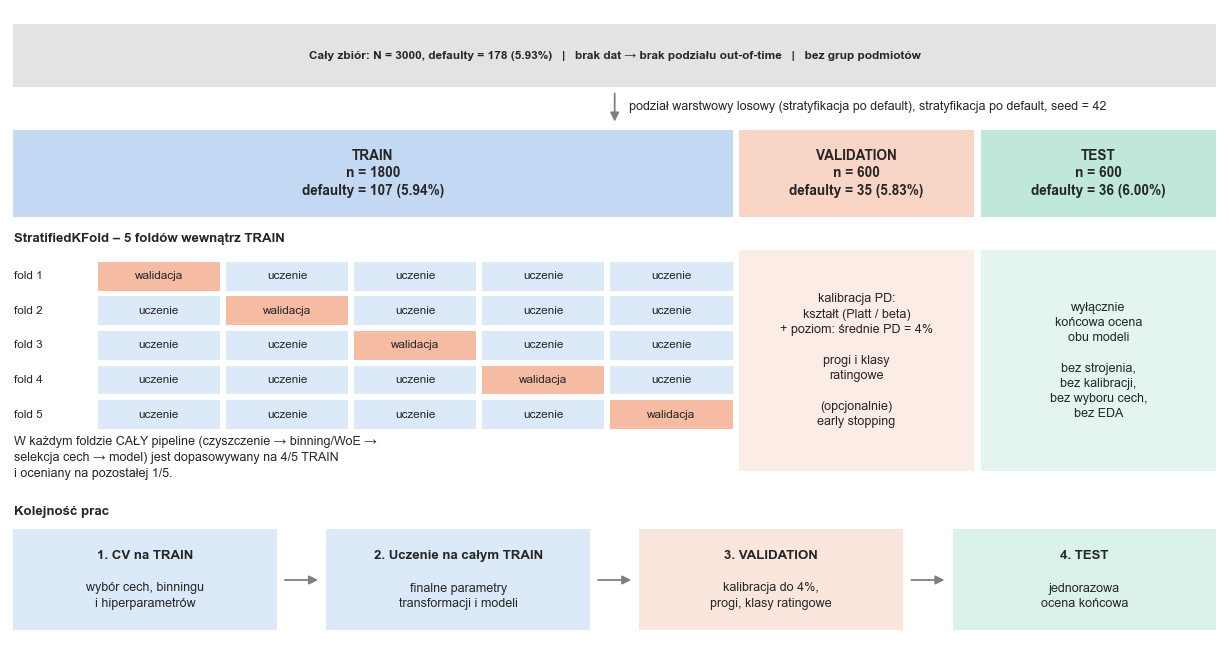

In [16]:
fig, ax = plt.subplots(figsize=(12.5, 6.8))
ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 67)
n = len(y_raw)
szer = lambda k: 100 * k / n
KOL = {"train": "#2a78d6", "valid": "#eb6834", "test": "#1baf7a"}

def pole(x, y, w, h, tekst, kolor, alpha=0.20, bold=False, fs=9.5):
    ax.add_patch(Rectangle((x + 0.25, y), w - 0.5, h, facecolor=kolor, alpha=alpha, edgecolor="none"))
    ax.text(x + w / 2, y + h / 2, tekst, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", linespacing=1.35)

def strzalka(x0, y0, x1, y1):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=13, lw=1.3, color="grey"))

opis_grup = (f"klastry podmiotów powiązanych (zawsze w jednym zbiorze): {int((GROUPS.value_counts() > 1).sum())}"
             if GROUPS is not None else "bez grup podmiotów")
pole(0, 59, 100, 6.5, f"Cały zbiór: N = {n}, defaulty = {int(y_raw.sum())} ({y_raw.mean():.2%})   |   "
     f"brak dat → brak podziału out-of-time   |   {opis_grup}", "grey", 0.22, True, 8.6)
strzalka(50, 58.6, 50, 55.1)
ax.text(51.2, 56.9, f"podział {SPLIT_MODE}, stratyfikacja po default, seed = {RNG_SEED}", fontsize=9, va="center")

x0, lewe = 0, {}
for nazwa, yy, etykieta in [("train", y_train, "TRAIN"), ("valid", y_valid, "VALIDATION"), ("test", y_test, "TEST")]:
    w = szer(len(yy))
    pole(x0, 45.5, w, 9.0, f"{etykieta}\nn = {len(yy)}\ndefaulty = {int(yy.sum())} ({yy.mean():.2%})", KOL[nazwa], 0.28, True, 9.8)
    lewe[nazwa] = (x0, w); x0 += w

xt, wt = lewe["train"]
ax.text(xt + 0.3, 43.2, f"{'StratifiedGroupKFold' if GROUPS is not None else 'StratifiedKFold'} – "
        f"{N_FOLDS} foldów wewnątrz TRAIN", fontsize=9.5, fontweight="bold", va="center")
fw = (wt - 7) / N_FOLDS
for k in range(N_FOLDS):
    yk = 37.8 - k * 3.6
    ax.text(xt + 0.3, yk + 1.5, f"fold {k + 1}", fontsize=8.5, va="center")
    for j in range(N_FOLDS):
        walid = j == k
        pole(xt + 7 + j * fw, yk, fw, 3.0, "walidacja" if walid else "uczenie",
             KOL["valid"] if walid else KOL["train"], 0.45 if walid else 0.16, False, 8.5)
ax.text(xt + 0.3, 20.4, "W każdym foldzie CAŁY pipeline (czyszczenie → binning/WoE →\nselekcja cech → model) "
        f"jest dopasowywany na {N_FOLDS-1}/{N_FOLDS} TRAIN\ni oceniany na pozostałej 1/{N_FOLDS}.",
        fontsize=9, va="center", linespacing=1.4)

xv, wv = lewe["valid"]; xs, ws = lewe["test"]
pole(xv, 19.0, wv, 23.0, f"kalibracja PD:\nkształt (Platt / beta)\n+ poziom: średnie PD = {TARGET_PD:.0%}\n\n"
     "progi i klasy\nratingowe\n\n(opcjonalnie)\nearly stopping", KOL["valid"], 0.12, False, 9)
pole(xs, 19.0, ws, 23.0, "wyłącznie\nkońcowa ocena\nobu modeli\n\nbez strojenia,\nbez kalibracji,\nbez wyboru cech,\nbez EDA",
     KOL["test"], 0.12, False, 9)

kroki = [("1. CV na TRAIN", "wybór cech, binningu\ni hiperparametrów", "train"),
         ("2. Uczenie na całym TRAIN", "finalne parametry\ntransformacji i modeli", "train"),
         ("3. VALIDATION", "kalibracja do 4%,\nprogi, klasy ratingowe", "valid"),
         ("4. TEST", "jednorazowa\nocena końcowa", "test")]
odstep = 3.6
wk = (100 - odstep * (len(kroki) - 1)) / len(kroki)
for i, (tytul, opis, z) in enumerate(kroki):
    xk = i * (wk + odstep)
    pole(xk, 2.5, wk, 10.5, "", KOL[z], 0.16)
    ax.text(xk + wk / 2, 10.2, tytul, ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(xk + wk / 2, 6.0, opis, ha="center", va="center", fontsize=9, linespacing=1.35)
    if i < len(kroki) - 1:
        strzalka(xk + wk + 0.2, 7.7, xk + wk + odstep - 0.2, 7.7)
ax.text(0.3, 14.8, "Kolejność prac", fontsize=9.5, fontweight="bold", va="center")
savefig("schemat_walidacji")
plt.show()

## 5. Kontrola data leakage

Sprawdzamy, czy: (1) ta sama obserwacja nie występuje w dwóch zbiorach, (2) żadna cecha nie zawiera informacji z przyszłości, (3) transformacje i selekcja cech nie korzystają z danych spoza zbioru treningowego (test permutacji w 9.2).

### 5.1. Rozłączność zbiorów, zgodność X–y i foldy bez udziału testu

In [23]:
from collections import Counter

assert X_raw.index.is_unique, "Indeksy w X_raw nie są unikalne."
assert X_raw.index.equals(y_raw.index)
sets = {
    "train": set(X_train.index),
    "val": set(X_valid.index),
    "test": set(X_test.index),
    "dev": set(X_dev.index),
}

assert sets["train"].isdisjoint(sets["val"])
assert sets["train"].isdisjoint(sets["test"])
assert sets["val"].isdisjoint(sets["test"])
assert sets["train"] | sets["val"] | sets["test"] == set(X_raw.index)
assert sets["train"] | sets["val"] == sets["dev"]
assert sets["dev"].isdisjoint(sets["test"])
assert len(X_train) + len(X_valid) + len(X_test) == len(X_raw)
assert set(X_train.columns) == set(X_valid.columns) == set(X_test.columns) == set(X_raw.columns)

for name, X, y in [
    ("train", X_train, y_train), ("validation", X_valid, y_valid),
    ("dev", X_dev, y_dev), ("test", X_test, y_test),
]:
    assert X.index.equals(y.index), f"Złe dopasowanie X/y: {name}"
    pd.testing.assert_frame_equal(X, X_raw.loc[X.index])
    pd.testing.assert_series_equal(y, y_raw.loc[y.index])


def check_cv_folds(folds, X, y, label):
    """Pozycje tr/va są lokalne dla X; sprawdzamy również grupy i pokrycie walidacją."""
    assert len(folds) == N_FOLDS, f"Niewłaściwa liczba foldów: {label}"
    universe = set(range(len(X)))
    all_valid = []
    for k, (tr, va) in enumerate(folds, 1):
        tr, va = np.asarray(tr), np.asarray(va)
        assert len(tr) > 0 and len(va) > 0
        assert np.issubdtype(tr.dtype, np.integer) and np.issubdtype(va.dtype, np.integer)
        assert len(set(tr)) == len(tr) and len(set(va)) == len(va)
        assert set(tr).isdisjoint(set(va)), f"Train i valid nachodzą na siebie: {label}/{k}"
        assert set(tr) | set(va) == universe, f"Fold nie pokrywa X: {label}/{k}"
        assert y.iloc[tr].nunique() == 2 and y.iloc[va].nunique() == 2, (
            f"Brakuje klasy 0 lub 1: {label}/{k}"
        )
        assert sets["test"].isdisjoint(set(X.index[tr]) | set(X.index[va]))
        if GROUPS is not None:
            gt, gv = set(GROUPS.loc[X.index[tr]]), set(GROUPS.loc[X.index[va]])
            assert gt.isdisjoint(gv), f"Te same grupy w dwóch częściach foldu {label}/{k}"
        all_valid.extend(va.tolist())
    counts = Counter(all_valid)
    assert set(counts) == universe, f"Nie wszystkie obserwacje walidowane: {label}"
    assert all(n == 1 for n in counts.values()), f"Rekord pojawił się wielokrotnie w walidacji: {label}"
    print(f"OK: {label} – {N_FOLDS} foldów, pełne pokrycie, każda obserwacja dokładnie raz w walidacji.")

check_cv_folds(cv_train, X_train, y_train, "cv_train")
check_cv_folds(cv_dev, X_dev, y_dev, "cv_dev")

# Sprawdzenie rzeczywistych proporcji: strict tylko przy niezgrupowanym podziale.
if GROUPS is None:
    assert abs(len(X_test)/len(X_raw) - TEST_SIZE) < 1 / len(X_raw) + 1e-12
    assert abs(len(X_valid)/len(X_raw) - (1-TEST_SIZE)*VALID_SIZE) < 1/len(X_raw) + 1e-12

print("OK: rozłączność train/validation/test, zgodność X–y, dane w CV bez udziału testu.")

OK: cv_train – 5 foldów, pełne pokrycie, każda obserwacja dokładnie raz w walidacji.
OK: cv_dev – 5 foldów, pełne pokrycie, każda obserwacja dokładnie raz w walidacji.
OK: rozłączność train/validation/test, zgodność X–y, dane w CV bez udziału testu.


### 5.2. Identyczne obserwacje w różnych zbiorach

Sprawdzamy, czy między train, validation i test nie powtarzają się identyczne wektory cech ani odciski z 2.2.

In [24]:
zbiory = {"train": X_train, "val": X_valid, "test": X_test}
row_hash = {k: pd.util.hash_pandas_object(v, index=False) for k, v in zbiory.items()}
raport_przeciekow = []
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    common_rows = set(row_hash[a]) & set(row_hash[b])
    common_fp = set(fp.loc[zbiory[a].index]) & set(fp.loc[zbiory[b].index])
    common_grp = (set(GROUPS.loc[zbiory[a].index]) & set(GROUPS.loc[zbiory[b].index])) if GROUPS is not None else set()
    raport_przeciekow.append({"para": f"{a}–{b}", "wspólne wektory X": len(common_rows),
                              "wspólne odciski": len(common_fp), "wspólne grupy podmiotów": len(common_grp)})
    assert not common_rows and not common_fp and not common_grp, f"Przeciek między {a} i {b}"
display(pd.DataFrame(raport_przeciekow).set_index("para"))
print("OK: brak wspólnych wektorów cech, odcisków i grup podmiotów między zbiorami.")

,wspólne wektory X,wspólne odciski,wspólne grupy podmiotów
para,,,
train–val,0,0,0
train–test,0,0,0
val–test,0,0,0


OK: brak wspólnych wektorów cech, odcisków i grup podmiotów między zbiorami.


### 5.3. Jednowymiarowa siła cech (TRAIN)

Dla każdej cechy liczbowej liczymy na train:
* AUC, siłę AUC = max(AUC, 1 − AUC) i kierunek zależności (`↑ ryzyko` – wyższa wartość, wyższe ryzyko),
* IV z binningu monotonicznego.

Alarm (wymagane sprawdzenie pod kątem przecieku): IV > 0,5 lub siła AUC ≥ 0,75. Alarm nie dotyczy cech usuwanych z powodu braków (≥ 50%), bo ich AUC jest liczone na kilkudziesięciu firmach.

In [25]:
Xtr_raw = X_train.copy()                      # surowe cechy TRAIN (bez targetu)
Xtr_feat = X_git.loc[X_train.index].copy()    # cechy surowe + bezstanowe TRAIN
ytr = y_train.copy()
assert Xtr_feat.index.equals(ytr.index) and TARGET not in Xtr_feat.columns

def univ_auc(s, y):
    s = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)
    m = s.notna()
    if m.sum() <= 20 or s[m].nunique() <= 1 or y[m].nunique() < 2:
        return np.nan
    return float(roc_auc_score(y[m], s[m]))

num_for_scan = [c for c in NUM_BLACK if c in Xtr_feat.columns]
assert len(num_for_scan) == len(NUM_BLACK)
uni = pd.DataFrame({"AUC": {c: univ_auc(Xtr_feat[c], ytr) for c in num_for_scan}})
uni["siła AUC"] = np.maximum(uni["AUC"], 1 - uni["AUC"])
uni["kierunek"] = np.select([uni["AUC"].isna(), uni["AUC"] >= 0.5], ["n/d", "↑ ryzyko"], "↓ ryzyko")
uni["IV"] = {c: fit_numeric_bins(Xtr_feat[c], ytr, BIN["max_bins"], BIN["min_bin_frac"],
                                 smoothing=BIN["smoothing"])["iv"] for c in num_for_scan}
uni["NaN (%)"] = 100 * Xtr_feat[num_for_scan].isna().mean()
uni["inf (%)"] = 100 * np.isinf(Xtr_feat[num_for_scan].astype(float)).mean()
uni["wsk. sektorowy"] = uni.index.isin(SUSPICIOUS)
uni["usuwana (braki)"] = uni["NaN (%)"] >= 100 * CLEAN["max_missing"]
uni["alarm"] = ~uni["usuwana (braki)"] & ((uni["IV"] > IV_SUSPICIOUS) | (uni["siła AUC"] >= AUC_ALARM))
uni = uni.sort_values("siła AUC", ascending=False)
assert uni["AUC"].dropna().between(0, 1).all()

print("15 najsilniejszych cech jednowymiarowo (TRAIN; bez cech usuwanych z powodu braków):")
display(uni[~uni["usuwana (braki)"]].head(15).round(4))
print("Cechy usuwane z powodu braków (AUC liczone na nielicznych firmach):")
display(uni[uni["usuwana (braki)"]].round(4))
print(f"Sygnały alarmowe (IV > {IV_SUSPICIOUS} lub siła AUC >= {AUC_ALARM}):")
display(uni[uni["alarm"]].round(4))

15 najsilniejszych cech jednowymiarowo (TRAIN; bez cech usuwanych z powodu braków):


,AUC,siła AUC,kierunek,IV,NaN (%),inf (%),wsk. sektorowy,usuwana (braki),alarm
wsk_index_nowe,0.6983,0.6983,↑ ryzyko,0.5542,0.0000,0.0000,True,False,True
wsk_index_skr_zaw,0.6673,0.6673,↑ ryzyko,0.4283,0.0000,0.0000,True,False,False
slog_Kapital_wlasny,0.3367,0.6633,↓ ryzyko,0.3589,0.0000,0.0000,False,False,False
slog_zysk_brutto,0.3638,0.6362,↓ ryzyko,0.2610,0.0000,0.0000,False,False,False
wsk_poziom_kapitalu_obrotowego_netto,0.3672,0.6328,↓ ryzyko,0.2668,0.0000,0.0000,False,False,False
wsk_struktura_kap_wlasnego_s_2,0.3685,0.6315,↓ ryzyko,0.2954,1.5000,3.0000,False,False,False
slog_podatek_dochodowy,0.3731,0.6269,↓ ryzyko,0.2313,0.0000,0.0000,False,False,False
wsk_ebit,0.3736,0.6264,↓ ryzyko,0.2783,0.0000,0.0000,False,False,False
slog_zysk_netto,0.3743,0.6257,↓ ryzyko,0.2324,0.0000,0.0000,False,False,False
slog_zysk_operacyjny,0.3776,0.6224,↓ ryzyko,0.2225,0.0000,0.0000,False,False,False


Cechy usuwane z powodu braków (AUC liczone na nielicznych firmach):


,AUC,siła AUC,kierunek,IV,NaN (%),inf (%),wsk. sektorowy,usuwana (braki),alarm
slog_RP_amortyzacja,0.3367,0.6633,↓ ryzyko,0.0406,95.7778,0.0000,False,True,False
wsk_zysk_CF_operacyjny,0.3661,0.6339,↓ ryzyko,0.1210,98.7222,0.0000,False,True,False
slog_RP_przeplywy_operacyjne,0.3705,0.6295,↓ ryzyko,0.1210,98.7222,0.0000,False,True,False
wsk_pokrycie_zob_kr_gotowkowe_2,0.4330,0.5670,↓ ryzyko,0.1210,98.7222,0.0000,False,True,False
wsk_pokrycie_wyd_fin_gotowkowe_2,0.5402,0.5402,↑ ryzyko,0.1210,98.7222,0.0000,False,True,False
wsk_zadluzenia_gotowki_2,0.4598,0.5402,↓ ryzyko,0.1210,98.7222,0.0000,False,True,False
wsk_akt_generowania_got_2,0.5134,0.5134,↑ ryzyko,0.1210,98.7222,0.0000,False,True,False


Sygnały alarmowe (IV > 0.5 lub siła AUC >= 0.75):


,AUC,siła AUC,kierunek,IV,NaN (%),inf (%),wsk. sektorowy,usuwana (braki),alarm
wsk_index_nowe,0.6983,0.6983,↑ ryzyko,0.5542,0.0000,0.0000,True,False,True


### 5.4. Wskaźniki sektorowe `wsk_index_*`

`wsk_index_nowe` ma IV > 0,5, a `wsk_index_nowe` i `wsk_index_skr_zaw` są najsilniejszymi cechami jednowymiarowymi. Sprawdzamy, czy wartości tych wskaźników są wspólne dla firm z tym samym kodem PKD.

In [26]:
I_COLS = SUSPICIOUS
t = Xtr_raw[["pkdKod"] + I_COLS].assign(default=ytr)
t["trojka"] = t.groupby(I_COLS).ngroup()      # numer unikalnej kombinacji (aktywne, skr_zaw, nowe)

pkd = t.groupby("pkdKod")["trojka"].agg(firmy="size", trojki="nunique").query("firmy >= 2")
wsp = t.groupby("trojka")["pkdKod"].agg(firmy="size", kody="nunique").query("firmy >= 2")

print(f"Kody PKD z >= 2 firmami: {len(pkd)}; jedna wspólna trójka w {(pkd['trojki'] == 1).mean():.1%} z nich.")
print(f"Różnych trójek: {t['trojka'].nunique()} na {len(t)} firm; firmy dzielące trójkę z inną: {wsp['firmy'].sum()}.")
print(f"Wspólne trójki: {len(wsp)}; w więcej niż jednym kodzie PKD: {(wsp['kody'] > 1).sum()}.")
display(t[I_COLS].corr(method="spearman").round(3))

top_pkd = t["pkdKod"].mode()[0]
print(f"Najliczniejszy kod PKD {top_pkd} – największe klastry wartości:")
display(t[t["pkdKod"] == top_pkd].groupby(I_COLS)["default"]
        .agg(firmy="size", defaulty="sum").nlargest(8, "firmy"))

Kody PKD z >= 2 firmami: 224; jedna wspólna trójka w 5.8% z nich.
Różnych trójek: 896 na 1800 firm; firmy dzielące trójkę z inną: 1164.
Wspólne trójki: 260; w więcej niż jednym kodzie PKD: 0.


,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe
wsk_index_aktywne,1.0000,0.4030,0.5490
wsk_index_skr_zaw,0.4030,1.0000,0.6490
wsk_index_nowe,0.5490,0.6490,1.0000


Najliczniejszy kod PKD 6820 – największe klastry wartości:


,,,firmy,defaulty
wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,,
0.0321,0.3428,0.2802,21,1
0.0291,0.2395,0.2085,17,0
0.0434,0.3968,0.4233,16,0
0.0272,0.2336,0.2053,3,0
0.0250,0.2390,0.1980,2,0
0.0324,0.3317,0.2843,2,0
0.0284,0.2320,0.2097,1,0
0.0287,0.2389,0.2105,1,0


**Wynik.** W obrębie jednego kodu PKD występuje kilka różnych zestawów wartości `wsk_index_*`, a żaden zestaw nie występuje w więcej niż jednym kodzie PKD. Wskaźniki są więc przypisane do branży, ale nie są stałe w jej obrębie. Okresu, za który zostały policzone, nie da się ustalić z danych.

**Decyzja:** wskaźniki zostają w modelu (`DROP_SUSPICIOUS = False`), pod warunkiem że opis zmiennych potwierdzi pomiar sprzed daty oceny. Ich wpływ na wyniki sprawdza test wrażliwości w 9.3. Jeśli pomiar dotyczy okresu po dacie oceny, należy ustawić `DROP_SUSPICIOUS = True` i uruchomić notebook ponownie.

In [27]:
DROP_SUSPICIOUS = False   # ręczna decyzja po weryfikacji okresu pomiaru wsk_index_* w opisie zmiennych

if DROP_SUSPICIOUS:
    NUM_INTERP = [c for c in NUM_INTERP if c not in SUSPICIOUS]
    NUM_BLACK = [c for c in NUM_BLACK if c not in SUSPICIOUS]
assert TARGET not in NUM_INTERP + NUM_BLACK
assert len(NUM_INTERP) == len(set(NUM_INTERP)) and len(NUM_BLACK) == len(set(NUM_BLACK))
print("Usunięcie wsk_index_*:", DROP_SUSPICIOUS,
      "| kandydaci liczbowi: interpretowalny", len(NUM_INTERP), "| black-box", len(NUM_BLACK))

Usunięcie wsk_index_*: False | kandydaci liczbowi: interpretowalny 140 | black-box 218


### 5.5. Podsumowanie kontroli leakage

| Etap | Dane | Reguła | Kontrola |
|---|---|---|---|
| Kontrola wejścia (rozdz. 2) | cały plik | tylko opis, bez decyzji modelowych | – |
| Podział (rozdz. 4) | `X_raw`, `y_raw` | warstwowo, z ustalonym ziarnem | asercje 5.1, kontrola 5.2 |
| Transformacje bezstanowe | pojedynczy wiersz | `log1p`, `signed_log1p`, dział PKD | brak statystyk z próby |
| Czyszczenie, capping, imputacja, binning, WoE, selekcja | train lub fold treningowy | parametry tylko w `.fit()` | test permutacji 9.2 |
| Cechy z przyszłości | opis zmiennych | moment dostępności cechy (rozdz. 1) | 5.3–5.4, test wrażliwości 9.3 |
| Strojenie | `cv_train` | pipeline dopasowywany od nowa w każdym foldzie | asercje 5.1 |
| Kalibracja, progi, klasy ratingowe | validation | nigdy na train ani test | – |
| Ocena końcowa | test | jednorazowo | – |

Do potwierdzenia w opisie zmiennych: okres pomiaru `wsk_index_*`, definicja defaultu i horyzont.

## 6. Jakość danych

Wszystkie statystyki są liczone na zbiorze treningowym. Rozdział opisuje problemy w danych i przyjęte reguły; transformacje wykonuje `FinancialCleaner` w `fit()` (zgodność sprawdza 6.6).

### 6.1. Profil jakości zmiennych liczbowych

Zmienne liczbowe: 217 | obserwacje train: 1800
NaN na train: 12501 | ±inf na train: 587
Do usunięcia – braki >= 50%: 7; quasi-stałe (dominanta >= 99%): 9; stałe: 0


,NaN (%),inf (%),skończone,dominanta (%),mediana,p99,max
wsk_akt_generowania_got_2,98.7220,0.0000,23,34.7830,0.0010,0.3300,0.3390
wsk_pokrycie_wyd_fin_gotowkowe_2,98.7220,0.0000,23,34.7830,0.4360,"7,418.7570","8,788.3550"
wsk_pokrycie_zob_kr_gotowkowe_2,98.7220,0.0000,23,34.7830,0.0010,8.9290,10.4400
wsk_zadluzenia_gotowki_2,98.7220,0.0000,23,52.1740,0.0000,"71,715.8670","74,124.5400"
wsk_zysk_CF_operacyjny,98.7220,0.0000,23,4.3480,0.2400,"221,245.5800","271,903.3270"
RP_przeplywy_operacyjne,98.7220,0.0000,23,34.7830,228.7100,"53,713,564.7410","67,128,118.3200"
RP_amortyzacja,95.7780,0.0000,76,23.6840,"253,933.7900","6,352,854.6980","9,335,372.9100"
wsk_plynnosc_biez_1,3.3890,29.3890,1210,30.4200,2.3540,229.7760,"5,717.5890"
wsk_struktura_kap_wlasnego_s_2,1.5000,3.0000,1719,4.6810,0.7950,41.5190,260.3380
wsk_kapital_do_aktywa,1.5000,0.2220,1769,8.7420,0.6570,1.0000,1.6520


Cechy quasi-stałe (dominanta >= 99%):


,skończone,zera (%),dominanta (%),unikalne
Naleznosci_dostaw_uslug_pow12m_kapitale,1800,99.9440,99.9440,2
Zobowiazania_dostaw_uslug_pow12m_kapitale,1800,99.9440,99.9440,2
Ujemna_wartosc_firmy,1800,99.8890,99.8890,3
Naleznosci_dostaw_uslug_pow12m_powiazane,1800,99.8890,99.8890,3
Zobowiazania_dostaw_uslug_pow12m_powiazane,1800,99.8330,99.8330,4
Pozostale_rezerwy,1800,99.4440,99.4440,11
Zobowiazania_dostaw_uslug_12m_kapitale,1800,99.3330,99.3330,13
Zobowiazania_dostaw_uslug_pow12m,1800,99.3330,99.3330,13
Wartosc_firmy,1800,99.0000,99.0000,19


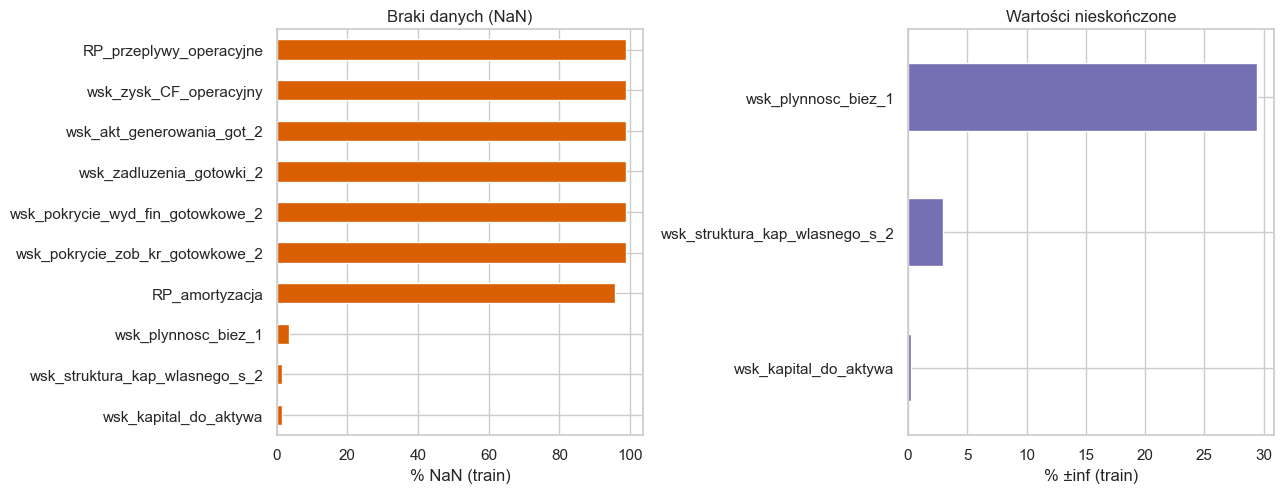

In [28]:
quality_cols = RATIO_COLS + LEVEL_COLS
Xtr_q = Xtr_raw[quality_cols].astype(float)
inf_tr = np.isinf(Xtr_q)
Xtr = Xtr_q.mask(inf_tr)                      # wartości skończone (inf -> NaN tylko na potrzeby statystyk)
n_fin = Xtr.notna().sum()
most_common_share = Xtr_q.apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] if s.notna().any() else np.nan)

dq = pd.DataFrame({
    "NaN (%)": 100 * Xtr_q.isna().mean(),
    "inf (%)": 100 * inf_tr.mean(),
    "skończone": n_fin,
    "zera (%)": 100 * (Xtr == 0).sum().div(n_fin.replace(0, np.nan)),
    "dominanta (%)": 100 * most_common_share,
    "unikalne": Xtr.nunique(),
    "min": Xtr.min(), "p01": Xtr.quantile(0.01), "mediana": Xtr.median(),
    "p99": Xtr.quantile(0.99), "max": Xtr.max(), "skosnosc": Xtr.skew(),
})
dq["usuniecie: braki"] = dq["NaN (%)"] >= 100 * CLEAN["max_missing"]
dq["usuniecie: quasi-stala"] = ~dq["usuniecie: braki"] & (dq["dominanta (%)"] >= 100 * CLEAN["quasi_const"])

assert dq.index.equals(Xtr_q.columns)
assert dq["NaN (%)"].between(0, 100).all() and dq["dominanta (%)"].dropna().between(0, 100).all()
assert (dq["skończone"] + Xtr_q.isna().sum() + inf_tr.sum() == len(Xtr_q)).all()
mq = dq[["p01", "mediana", "p99"]].notna().all(axis=1)
assert (dq.loc[mq, "p01"] <= dq.loc[mq, "mediana"]).all() and (dq.loc[mq, "mediana"] <= dq.loc[mq, "p99"]).all()

print(f"Zmienne liczbowe: {len(quality_cols)} | obserwacje train: {len(Xtr_q)}")
print(f"NaN na train: {int(Xtr_q.isna().sum().sum())} | ±inf na train: {int(inf_tr.sum().sum())}")
print(f"Do usunięcia – braki >= {CLEAN['max_missing']:.0%}: {int(dq['usuniecie: braki'].sum())}; "
      f"quasi-stałe (dominanta >= {CLEAN['quasi_const']:.0%}): {int(dq['usuniecie: quasi-stala'].sum())}; "
      f"stałe: {int((dq['unikalne'] <= 1).sum())}")
display(dq.loc[(dq["NaN (%)"] > 0) | (dq["inf (%)"] > 0),
               ["NaN (%)", "inf (%)", "skończone", "dominanta (%)", "mediana", "p99", "max"]]
        .sort_values(["NaN (%)", "inf (%)"], ascending=False).round(3))
print("Cechy quasi-stałe (dominanta >= 99%):")
display(dq.loc[dq["usuniecie: quasi-stala"], ["skończone", "zera (%)", "dominanta (%)", "unikalne"]]
        .sort_values("dominanta (%)", ascending=False).round(3))

miss = dq["NaN (%)"][dq["NaN (%)"] > 0].sort_values()
infs = dq["inf (%)"][dq["inf (%)"] > 0].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 0.35 * max(len(miss), len(infs)) + 1.6))
miss.plot.barh(ax=axes[0], color="#d95f02"); axes[0].set_xlabel("% NaN (train)"); axes[0].set_title("Braki danych (NaN)")
infs.plot.barh(ax=axes[1], color="#7570b3"); axes[1].set_xlabel("% ±inf (train)"); axes[1].set_title("Wartości nieskończone")
savefig("dq_braki_inf")
plt.show()

Siedem zmiennych z rachunku przepływów pieniężnych ma 96–99% braków, a dziewięć pozycji kwotowych ma ≥ 99% zer – wszystkie zostaną usunięte. Pozostałe braki i wartości nieskończone dotyczą trzech wskaźników (6.2).

### 6.2. Wartości specjalne `±inf` i `NaN`

Sprawdzamy, czy `+inf` i `NaN` we wskaźnikach wynikają z zerowego mianownika, i porównujemy stopę defaultu (z 95% przedziałem Wilsona) w tych grupach.

In [29]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

MIANOWNIK = {   # wskaźnik -> pozycja bilansowa w mianowniku (zweryfikowane poniżej na danych)
    "wsk_plynnosc_biez_1": "Zobowiazania_krotkoterminowe",
    "wsk_kapital_do_aktywa": "Aktywa",
    "wsk_struktura_kap_wlasnego_s_2": "Aktywa_trwale",
}
wiersze = []
for w, mian in MIANOWNIK.items():
    x = Xtr_raw[w].astype(float); m0 = Xtr_raw[mian].eq(0)
    for nazwa, maska in [("+inf", np.isposinf(x)), ("NaN", x.isna()), ("wartość skończona", np.isfinite(x))]:
        k, n_ = int(ytr[maska].sum()), int(maska.sum())
        lo, hi = wilson(k, n_)
        wiersze.append({"wskaźnik": w, "wartość": nazwa, "n": n_,
                        "% z mianownikiem = 0": 100 * m0[maska].mean() if n_ else np.nan,
                        "DR": k / n_ if n_ else np.nan, "DR 95% CI": f"[{lo:.3f}; {hi:.3f}]" if n_ else ""})
display(pd.DataFrame(wiersze).set_index(["wskaźnik", "wartość"]).round(4))
for w, mian in MIANOWNIK.items():
    x = Xtr_raw[w].astype(float)
    assert Xtr_raw.loc[np.isposinf(x), mian].eq(0).all(), f"{w}: +inf bez zerowego mianownika"
    assert Xtr_raw.loc[x.isna(), mian].eq(0).all(), f"{w}: NaN bez zerowego mianownika"
print("OK: każde +inf i każde NaN w tych wskaźnikach odpowiada zerowemu mianownikowi.")

n  % z mianownikiem = 0     DR       DR 95% CI
wskaźnik                       wartość                                                             
wsk_plynnosc_biez_1            +inf                529              100.0000 0.0718  [0.053; 0.097]
                               NaN                  61              100.0000 0.0656  [0.026; 0.157]
                               wartość skończona  1210                0.2479 0.0537  [0.042; 0.068]
wsk_kapital_do_aktywa          +inf                  4              100.0000 0.0000  [0.000; 0.490]
                               NaN                  27              100.0000 0.1111  [0.039; 0.281]
                               wartość skończona  1769                0.0000 0.0588  [0.049; 0.071]
wsk_struktura_kap_wlasnego_s_2 +inf                 54              100.0000 0.0926  [0.040; 0.199]
                               NaN                  27              100.0000 0.1111  [0.039; 0.281]
                               wartość skończona  1719               29.6684 0.0576  [0.048; 0.070]

OK: każde +inf i każde NaN w tych wskaźnikach odpowiada zerowemu mianownikowi.


**Wniosek.** Wszystkie `+inf` i `NaN` w tych wskaźnikach odpowiadają zerowemu mianownikowi, np. `+inf` w `wsk_plynnosc_biez_1` oznacza brak zobowiązań krótkoterminowych (29% train). DR firm z `+inf` płynności (7,2%) jest wyższy niż firm z wartością skończoną (5,4%), dlatego wartości specjalnych nie traktujemy jak zwykłych braków ani jak najwyższej płynności:
* karta WoE: osobne przedziały `+INF` i `BRAK` z własnym WoE,
* black-box: `+inf` → górna granica cappingu + flaga `__inf`, `NaN` → mediana + flaga `__isna`.

### 6.3. Spójność księgowa i wartości niemożliwe

Sprawdzamy tożsamości bilansowe (dla aktywów ≠ 0) oraz ujemne wartości w pozycjach, które powinny być nieujemne. Odchylenie tożsamości > 1% oznacza rekord do weryfikacji.

In [30]:
required_balance = ["Aktywa", "Aktywa_trwale", "Aktywa_obrotowe", "Kapital_wlasny", "Zobowiazania_rezerwy"]
assert set(required_balance) <= set(Xtr_raw.columns)
fin = Xtr_raw[required_balance].astype(float).replace([np.inf, -np.inf], np.nan)
valid_1 = fin[["Aktywa", "Aktywa_trwale", "Aktywa_obrotowe"]].notna().all(axis=1) & fin["Aktywa"].ne(0)
valid_2 = fin[["Aktywa", "Kapital_wlasny", "Zobowiazania_rezerwy"]].notna().all(axis=1) & fin["Aktywa"].ne(0)
gap1 = ((fin["Aktywa"] - fin["Aktywa_trwale"] - fin["Aktywa_obrotowe"]).abs() / fin["Aktywa"].abs()).where(valid_1)
gap2 = ((fin["Aktywa"] - fin["Kapital_wlasny"] - fin["Zobowiazania_rezerwy"]).abs() / fin["Aktywa"].abs()).where(valid_2)
bilanse = pd.DataFrame({
    "tożsamość": ["Aktywa = trwałe + obrotowe", "Aktywa = kapitał własny + zobowiązania i rezerwy"],
    "sprawdzonych": [int(valid_1.sum()), int(valid_2.sum())],
    "pominiętych (aktywa = 0)": [int((~valid_1).sum()), int((~valid_2).sum())],
    "odchylenie > 1%": [int((gap1 > 0.01).sum()), int((gap2 > 0.01).sum())],
    "DR przy odchyleniu > 1%": [ytr[gap1 > 0.01].mean(), ytr[gap2 > 0.01].mean()],
    "max odchylenie (%)": [100 * gap1.max(), 100 * gap2.max()],
}).set_index("tożsamość")
assert (bilanse["sprawdzonych"] + bilanse["pominiętych (aktywa = 0)"] == len(Xtr_raw)).all()
display(bilanse.round(3))

nonneg_candidates = [c for c in LEVEL_COLS if c.startswith(
    ("Aktywa", "Zapasy", "Srodki_", "Zobowiazania", "Kredyty", "Naleznosci", "Kapital_podstawowy", "przychody"))]
negative_counts = (Xtr[nonneg_candidates] < 0).sum().sort_values(ascending=False)
print("Ujemne wartości w pozycjach, które powinny być nieujemne (train):")
display(negative_counts[negative_counts > 0].to_frame("liczba ujemnych"))
anomalie = pd.DataFrame({
    "warunek": ["Aktywa = 0", "Aktywa < 0", "Kapitał własny < 0", "wiek firmy <= 0 dni",
                "jakakolwiek ujemna pozycja nieujemna"],
    "liczba": [int(fin["Aktywa"].eq(0).sum()), int(fin["Aktywa"].lt(0).sum()), int(fin["Kapital_wlasny"].lt(0).sum()),
               int((Xtr_raw["wsk_liczba_dni_istnienia"] <= 0).sum()), int((Xtr[nonneg_candidates] < 0).any(axis=1).sum())],
}).set_index("warunek")
anomalie["DR"] = [ytr[fin["Aktywa"].eq(0)].mean(), ytr[fin["Aktywa"].lt(0)].mean(), ytr[fin["Kapital_wlasny"].lt(0)].mean(),
                  ytr[Xtr_raw["wsk_liczba_dni_istnienia"] <= 0].mean(), ytr[(Xtr[nonneg_candidates] < 0).any(axis=1)].mean()]
display(anomalie.round(4))

,sprawdzonych,pominiętych (aktywa = 0),odchylenie > 1%,DR przy odchyleniu > 1%,max odchylenie (%)
tożsamość,,,,,
Aktywa = trwałe + obrotowe,1769,31,48,0.0210,100.0000
Aktywa = kapitał własny + zobowiązania i rezerwy,1769,31,42,0.0710,586.8630


Ujemne wartości w pozycjach, które powinny być nieujemne (train):


,liczba ujemnych
przychody_sprzedazy,5
Srodki_pieniezne,4
przychody_finansowe,3
Aktywa_trwale,2
przychody,2
Zobowiazania_dostaw_uslug_12m_pozostale,1
Srodki_trwale,1
Zobowiazania_rezerwy,1


,liczba,DR
warunek,,
Aktywa = 0,31,0.0968
Aktywa < 0,0,NaN
Kapitał własny < 0,0,NaN
wiek firmy <= 0 dni,0,NaN
jakakolwiek ujemna pozycja nieujemna,15,0.0000


**Reguły dla anomalii**

| Anomalia | Liczba (train) | Decyzja |
|---|---|---|
| Aktywa = 0 | 31 | zostają; wskaźniki z aktywami w mianowniku mają wartości specjalne obsłużone jak w 6.2 |
| Odchylenie tożsamości bilansowej > 1% | 48 / 42 | zostają bez korekty; DR tych grup (2,1% / 7,1%) nie odbiega wyraźnie od średniej |
| Ujemne kwoty w pozycjach nieujemnych | 15 | zostają; w black-boxie `signed_log1p` zachowuje znak, karta nie używa pozycji kwotowych |
| Aktywa < 0 | 0 (1 w pliku) | `log_aktywa` = NaN |

Obserwacji nie usuwamy, bo ta sama reguła musiałaby być stosowana przy ocenie nowych firm.

### 6.4. Ogony rozkładów i wartości odstające

Miara: odległość wartości minimalnej i maksymalnej od p01 / p99, wyrażona w szerokościach przedziału [p01, p99].

In [31]:
spread = (dq["p99"] - dq["p01"]).replace(0, np.nan)
xtail = pd.DataFrame({"górny ogon": (dq["max"] - dq["p99"]) / spread,
                      "dolny ogon": (dq["p01"] - dq["min"]) / spread})
xtail["max miara"] = xtail.max(axis=1)
xtail = xtail.sort_values("max miara", ascending=False)
display(xtail.head(12).round(1))
print("Cechy z ogonem > 10 szerokości p01–p99:", int((xtail["max miara"] > 10).sum()),
      "| cechy o zerowej szerokości p01–p99:", int((dq["p99"] == dq["p01"]).sum()))
print("Polityka: black-box – capping do [p01, p99] z TRAIN; karta – binning kwantylowy (odporny na ogony).")

,górny ogon,dolny ogon,max miara
wsk_pokrycia_zobowiazan_rz_aktywami_trwalymi,"161,407,462,756.6000","104,547,247,984.3000","161,407,462,756.6000"
Zobowiazania_dostaw_uslug_pow12m_pozostale,"28,885.7000",0.0000,"28,885.7000"
wsk_koszty_odsetki_przychody,"15,887.4000",200.6000,"15,887.4000"
wsk_zadluzenie_gotowka,"15,887.4000",200.6000,"15,887.4000"
wsk_ebitda_zobowiazan_odsetki_2,"8,070.9000",55.0000,"8,070.9000"
wsk_ebitda_koszty_odsetkowe_2,"8,070.9000",55.0000,"8,070.9000"
wsk_pokrycia_odsetek_zyskiem,"4,910.1000",72.4000,"4,910.1000"
wsk_obrotowsci_naleznosci,"4,562.3000",0.0000,"4,562.3000"
wsk_ebitda_zobowiazan_odsetki_1,"4,417.3000",56.3000,"4,417.3000"
wsk_ebitda_koszty_odsetkowe_1,"4,417.3000",56.3000,"4,417.3000"


Cechy z ogonem > 10 szerokości p01–p99: 147 | cechy o zerowej szerokości p01–p99: 9
Polityka: black-box – capping do [p01, p99] z TRAIN; karta – binning kwantylowy (odporny na ogony).


### 6.5. Zmienne kategoryczne

Liczba poziomów oraz liczba poziomów spełniających próg `MIN_CAT_SHARE` (5% train); rzadsze poziomy trafiają do `INNE`.

In [32]:
cat_audit_cols = list(dict.fromkeys(CAT_RAW + CAT_COLS))
min_cat_n = int(np.ceil(MIN_CAT_SHARE * len(Xtr_feat)))
cat_report = pd.DataFrame({
    "liczba poziomów": Xtr_feat[cat_audit_cols].nunique(dropna=True),
    "braki": Xtr_feat[cat_audit_cols].isna().sum(),
    "udział najczęstszego (%)": [100 * Xtr_feat[c].value_counts(normalize=True).iloc[0] for c in cat_audit_cols],
    f"poziomy >= {min_cat_n} obs.": [(Xtr_feat[c].value_counts() >= min_cat_n).sum() for c in cat_audit_cols],
})
display(cat_report.round(1))
print(f"Spójność schematów: schemat bilansu = schemat RZiS w "
      f"{(Xtr_feat['schemat_wsk_bilans'] == Xtr_feat['schemat_wsk_rzis']).mean():.1%} rekordów.")

,liczba poziomów,braki,udział najczęstszego (%),poziomy >= 90 obs.
szczegolnaFormaPrawna_Symbol,1,0,100.0000,1
formaWlasnosci_Symbol,15,0,67.2000,4
pkdKod,330,0,4.3000,0
schemat_wsk_bilans,3,0,54.2000,3
schemat_wsk_rzis,3,0,55.7000,3
pkd_div,74,0,11.3000,4
forma_wl,15,0,67.2000,4


Spójność schematów: schemat bilansu = schemat RZiS w 97.8% rekordów.


### 6.6. Kontrola `FinancialCleaner`

Sprawdzamy, czy `FinancialCleaner` usuwa te same cechy, które wskazały 6.1 i 2.3, oraz czy wynik w trybie black-box nie zawiera `NaN` ani `inf`.

In [33]:
test_cleaner = FinancialCleaner(**CLEAN, impute=True, inf_policy="cap").fit(Xtr_feat[NUM_BLACK])
Xb = Xtr_feat[NUM_BLACK].astype(float)
manual_missing = Xb.isna().mean()
assert set(test_cleaner.dropped_["za_duzo_brakow"]) == set(manual_missing[manual_missing >= CLEAN["max_missing"]].index)
rest = [c for c in NUM_BLACK if c not in test_cleaner.dropped_["za_duzo_brakow"]]
manual_dom = Xb[rest].apply(lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else 1.0)
assert set(test_cleaner.dropped_["quasi_stale"]) == set(manual_dom[manual_dom >= CLEAN["quasi_const"]].index)
dup_pairs = pd.DataFrame({"duplikat": DUPLICATES, "odpowiada kolumnie": cechy_zduplikowane})
dup_in_scope = dup_pairs[dup_pairs["duplikat"].isin(NUM_BLACK) & dup_pairs["odpowiada kolumnie"].isin(NUM_BLACK)]
assert set(dup_in_scope["duplikat"]) <= set(test_cleaner.dropped_["duplikat"]), "Duplikat z pliku nie został usunięty."
Z_clean_test = test_cleaner.transform(Xtr_feat[NUM_BLACK])
assert Z_clean_test.index.equals(X_train.index) and Z_clean_test.columns.is_unique
assert np.isfinite(Z_clean_test.to_numpy(dtype=float)).all()
print("Usunięte za braki:", len(test_cleaner.dropped_["za_duzo_brakow"]))
print("Usunięte quasi-stałe:", len(test_cleaner.dropped_["quasi_stale"]))
print("Usunięte duplikaty kolumn (na train):", test_cleaner.dropped_["duplikat_kolumny"])
extra_dup = sorted(set(test_cleaner.dropped_["duplikat"]) - set(dup_in_scope["duplikat"]))
print("Duplikaty wykryte na train, a nieobecne w całym pliku:", extra_dup or "brak")
print("Flagi __isna:", test_cleaner.nan_ind_cols_, "| flagi __inf:", test_cleaner.inf_ind_cols_)
print("Kolumny po FinancialCleaner (z flagami):", Z_clean_test.shape[1])
print("OK: polityka czyszczenia zgodna z niezależnym audytem train; wynik bez NaN i inf.")

Usunięte za braki: 7
Usunięte quasi-stałe: 9
Usunięte duplikaty kolumn (na train): {'wsk_rent_sprzedazy': 'wsk_ROS', 'wsk_zysk_operacyjny_zob_1': 'wsk_zysk_op_zobowiazania', 'wsk_zadluzenie_gotowka': 'wsk_koszty_odsetki_przychody', 'wsk_ebitda_zobowiazan_odsetki_1': 'wsk_ebitda_koszty_odsetkowe_1', 'wsk_ebitda_zobowiazan_odsetki_2': 'wsk_ebitda_koszty_odsetkowe_2', 'wsk_poziom_kosztow_operacyjnych': 'wsk_koszty_przychody', 'wsk_poziom_kosztow_finansowych': 'wsk_koszty_fin_przychody', 'wsk_struktura_kap_wlasnego_1': 'wsk_udzial_kap_wlasnego_aktywa_1', 'slog_Aktywa': 'log_aktywa'}
Duplikaty wykryte na train, a nieobecne w całym pliku: ['slog_Aktywa']
Flagi __isna: ['wsk_plynnosc_biez_1'] | flagi __inf: ['wsk_plynnosc_biez_1', 'wsk_struktura_kap_wlasnego_s_2']
Kolumny po FinancialCleaner (z flagami): 196
OK: polityka czyszczenia zgodna z niezależnym audytem train; wynik bez NaN i inf.


Na train usuwany jest dodatkowo `slog_Aktywa`, identyczny z `log_aktywa` – jedyna firma z ujemnymi aktywami (dla której te kolumny się różnią) nie trafiła do train.

## 7. EDA

Analiza obejmuje wyłącznie zbiór treningowy.

### 7.1. Zmienna celu

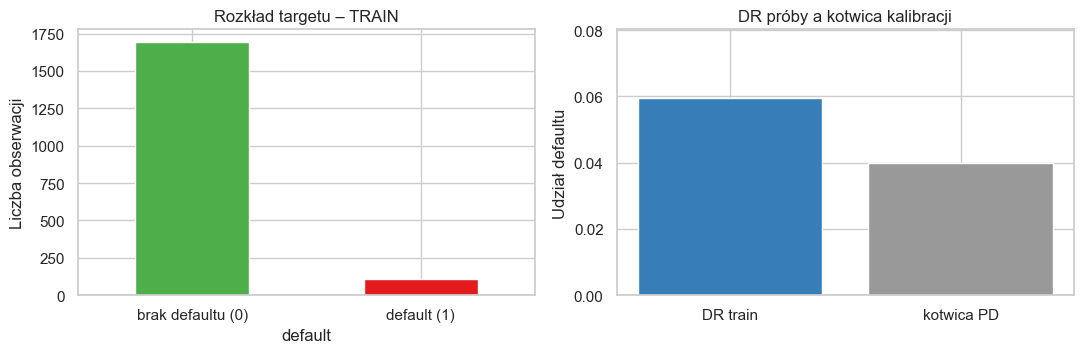

TRAIN: 1800 obserwacji, 107 defaultów, DR = 5.94%; różnica do kotwicy 4%: +1.94 p.p.


In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
ytr.value_counts().reindex([0, 1], fill_value=0).plot.bar(ax=ax[0], color=["#4daf4a", "#e41a1c"])
ax[0].set_xticklabels(["brak defaultu (0)", "default (1)"], rotation=0)
ax[0].set_title("Rozkład targetu – TRAIN"); ax[0].set_ylabel("Liczba obserwacji")
ax[1].bar(["DR train", "kotwica PD"], [ytr.mean(), TARGET_PD], color=["#377eb8", "#999999"])
ax[1].set_ylabel("Udział defaultu"); ax[1].set_ylim(0, max(ytr.mean(), TARGET_PD) * 1.35)
ax[1].set_title("DR próby a kotwica kalibracji")
savefig("eda_target")
plt.show()
print(f"TRAIN: {len(ytr)} obserwacji, {int(ytr.sum())} defaultów, DR = {ytr.mean():.2%}; "
      f"różnica do kotwicy {TARGET_PD:.0%}: {100*(ytr.mean() - TARGET_PD):+.2f} p.p.")

### 7.2. Zależności z targetem i rozkłady cech

Ranking według AUC z 5.3 (na górze cechy, których wyższa wartość oznacza wyższe ryzyko) oraz korelacja Spearmana z targetem. Wykresy pokazują rozkłady 8 cech o najwyższym AUC w klasach default / brak defaultu (przycięte do p01–p99 dla czytelności).

,AUC,Spearman_z_default
wsk_index_nowe,0.6983,0.1624
wsk_index_skr_zaw,0.6673,0.1370
wsk_ogolnego_zadluzenia_1,0.5961,0.0788
wsk_zadluzenie_kap_wlasnego,0.5959,0.0786
wsk_zadluzenia,0.5959,0.0786
wsk_struktura_kap_obcego_s,0.5945,0.0774
wsk_ogolnego_zadluzenia_2,0.5944,0.0774
wsk_zob_s_aktywa_rzeczowe,0.5940,0.0770
wsk_mnoznik_kap_wl,0.5937,0.0767
wsk_poziom_kosztow_operacyjnych,0.5871,0.0714


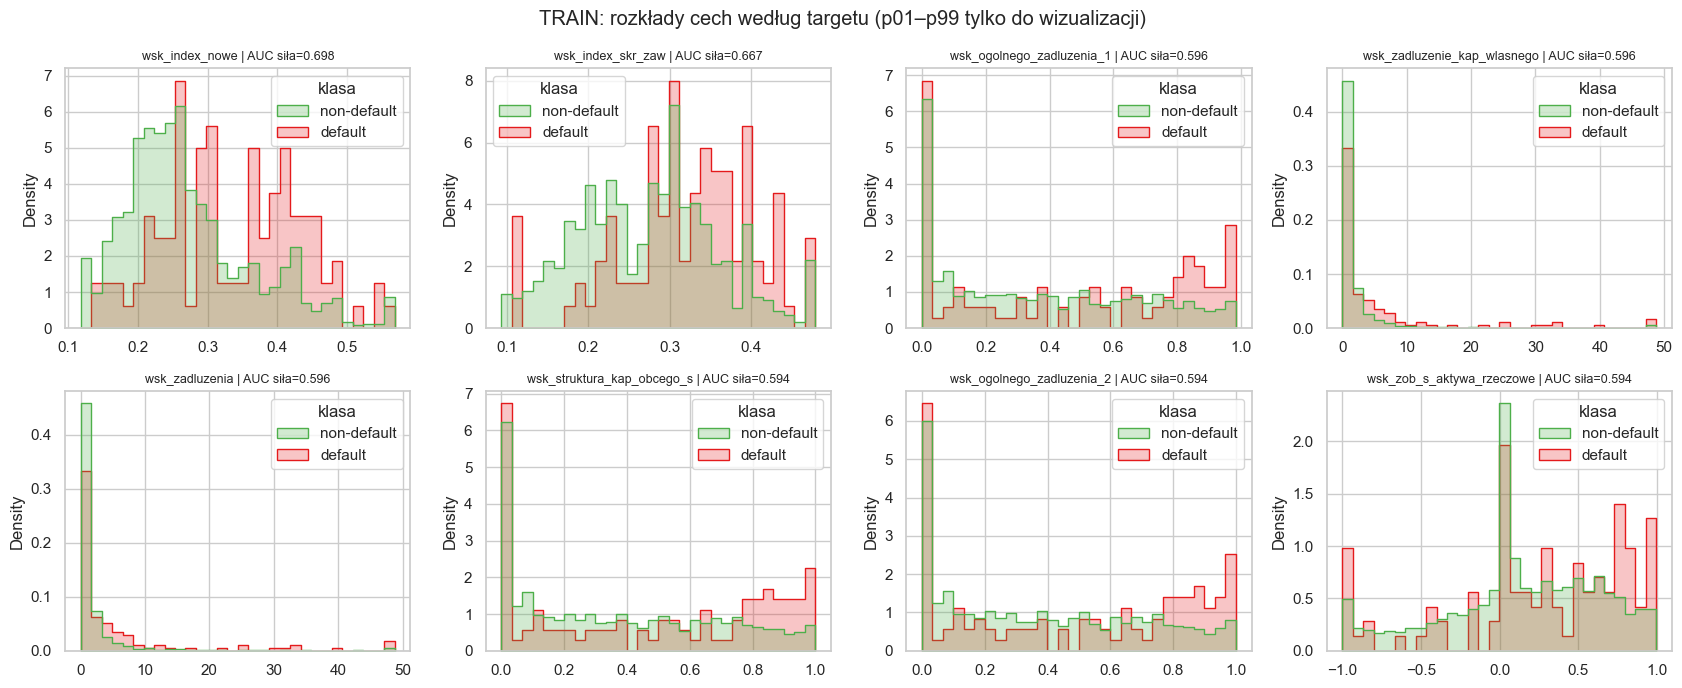

In [35]:
from scipy import stats

ranking = uni.dropna(subset=["AUC"]).sort_values("AUC", ascending=False)
top = [c for c in ranking.index if c in Xtr_feat.columns][:8]
assert len(top) > 0, "Brak cech z obliczalnym jednowymiarowym AUC."

def safe_spearman(x, y):
    x = pd.to_numeric(x, errors="coerce").replace([np.inf, -np.inf], np.nan)
    m = x.notna() & y.notna()
    if m.sum() < 3 or x[m].nunique() < 2 or y[m].nunique() < 2:
        return np.nan
    return float(stats.spearmanr(x[m], y[m]).statistic)

sp = pd.Series({c: safe_spearman(Xtr_feat[c], ytr) for c in ranking.index[:30]}, name="Spearman_z_default")
top_assoc = ranking.loc[sp.index, ["AUC"]].join(sp)
display(top_assoc.head(20).round(4))

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), top):
    x = pd.to_numeric(Xtr_feat[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
    lo, hi = x.quantile([0.01, 0.99])
    plot_df = pd.DataFrame({"x": x.clip(lo, hi),
                            "klasa": np.where(ytr.to_numpy() == 1, "default", "non-default")}, index=x.index).dropna()
    if not plot_df.empty:
        sns.histplot(data=plot_df, x="x", hue="klasa", stat="density", common_norm=False,
                     bins=30, element="step", ax=ax,
                     palette={"default": "#e41a1c", "non-default": "#4daf4a"})
    ax.set_title(f"{c} | AUC siła={ranking.loc[c, 'AUC']:.3f}", fontsize=9)
    ax.set_xlabel("")
for ax in axes.ravel()[len(top):]:
    ax.axis("off")
fig.suptitle("TRAIN: rozkłady cech według targetu (p01–p99 tylko do wizualizacji)")
savefig("eda_top_features")
plt.show()

### 7.3. Stopa defaultu w kategoriach

DR z 95% przedziałem Wilsona dla kategorii z co najmniej 30 obserwacjami.

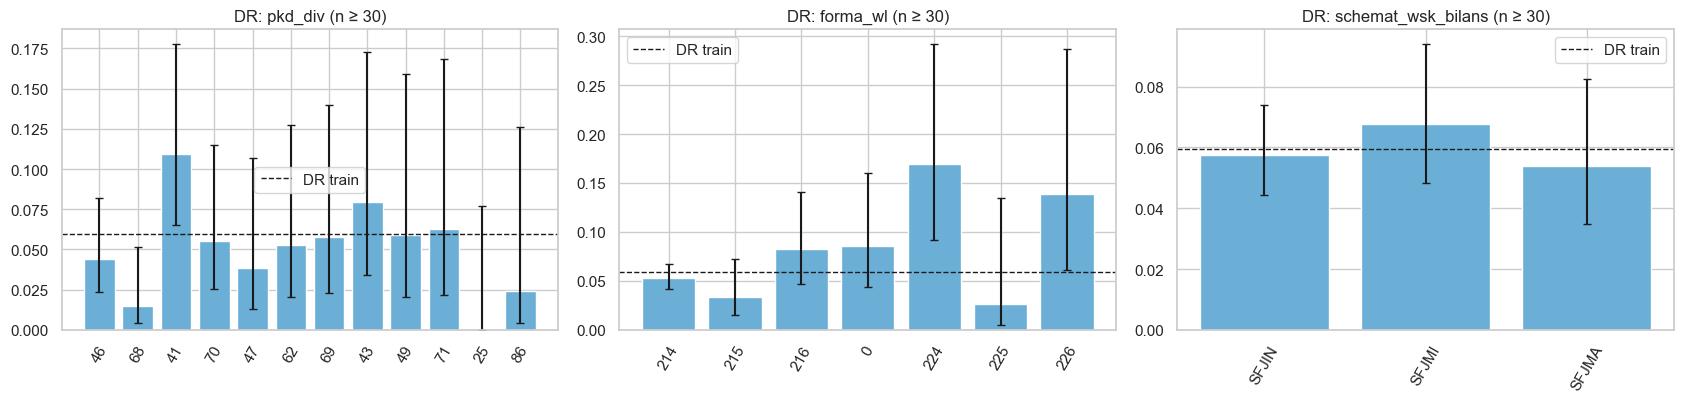

,n,defaulty,DR,CI dolny,CI gorny
pkd_div,,,,,
46,203,9,0.0443,0.0235,0.0821
68,137,2,0.0146,0.0040,0.0517
41,119,13,0.1092,0.0650,0.1780
70,109,6,0.0550,0.0255,0.1149
47,78,3,0.0385,0.0132,0.1071
62,76,4,0.0526,0.0207,0.1277
69,69,4,0.0580,0.0228,0.1398
43,63,5,0.0794,0.0344,0.1727
49,51,3,0.0588,0.0202,0.1592


,n,defaulty,DR,CI dolny,CI gorny
schemat_wsk_bilans,,,,,
SFJIN,975,56,0.0574,0.0445,0.0739
SFJMI,472,32,0.0678,0.0484,0.0941
SFJMA,353,19,0.0538,0.0347,0.0825


In [36]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return c - h, c + h

def rate_table(col, min_n=30):
    g = Xtr_feat.assign(y=ytr).groupby(col)["y"].agg(["count", "sum"]).rename(columns={"count": "n", "sum": "defaulty"})
    g = g[g["n"] >= min_n].copy()
    g["DR"] = g["defaulty"] / g["n"]
    g["CI dolny"], g["CI gorny"] = zip(*[wilson(k, n_) for k, n_ in zip(g["defaulty"], g["n"])])
    return g.sort_values("n", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, c in zip(axes, ["pkd_div", "forma_wl", "schemat_wsk_bilans"]):
    g = rate_table(c).head(12)
    ax.bar(g.index.astype(str), g["DR"], yerr=[g["DR"] - g["CI dolny"], g["CI gorny"] - g["DR"]], capsize=3, color="#6baed6")
    ax.axhline(ytr.mean(), color="k", ls="--", lw=1, label="DR train")
    ax.set_title(f"DR: {c} (n ≥ 30)"); ax.tick_params(axis="x", rotation=60); ax.legend()
savefig("eda_dr_kategorie")
plt.show()
display(rate_table("pkd_div").head(10).round(4))
display(rate_table("schemat_wsk_bilans").round(4))

### 7.4. Korelacje Spearmana

Korelacje między wskaźnikami z co najmniej 90% wartości skończonych; |ρ| > 0,90 oznacza silną redundancję. Selekcję cech karty z uwzględnieniem korelacji wykonuje `WoEEncoder` (rozdział 8).

Liczba analizowanych wskaźników: 133


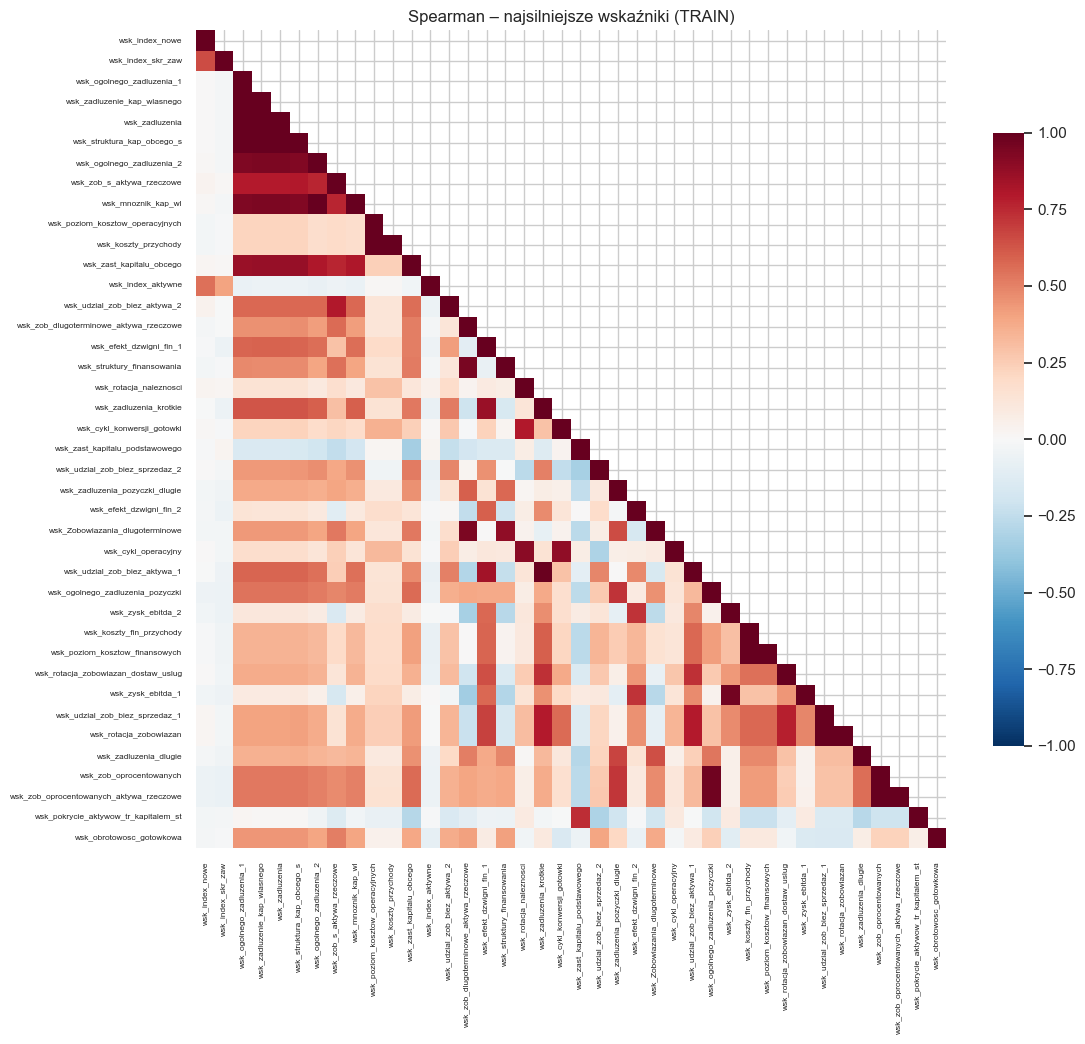

Pary |ρ| > 0.90: 203 / 8778 dostępnych par.


rho
wsk_kapital_do_aktywa            wsk_udzial_kap_wlasnego_aktywa_1 1.0000
                                 wsk_struktura_kap_wlasnego_1     1.0000
wsk_ROS                          wsk_rent_sprzedazy               1.0000
wsk_koszty_odsetki_przychody     wsk_zadluzenie_gotowka           1.0000
wsk_udzial_kap_wlasnego_aktywa_1 wsk_struktura_kap_wlasnego_1     1.0000
wsk_ebitda_koszty_odsetkowe_1    wsk_ebitda_zobowiazan_odsetki_1  1.0000
wsk_ebitda_koszty_odsetkowe_2    wsk_ebitda_zobowiazan_odsetki_2  1.0000
wsk_koszty_fin_przychody         wsk_poziom_kosztow_finansowych   1.0000
wsk_zysk_op_zobowiazania         wsk_zysk_operacyjny_zob_1        1.0000
wsk_koszty_przychody             wsk_poziom_kosztow_operacyjnych  1.0000
wsk_zadluzenie_kap_wlasnego      wsk_zadluzenia                   1.0000
wsk_pokrycie_aktywow_kap_stalym  wsk_zast_kapitalu_wlasnego       1.0000
wsk_struktura_kap_wlasnego_1     wsk_struktura_kap_wlasnego_2     1.0000
wsk_udzial_kap_wlasnego_aktywa_1 wsk_struktura_kap_wlasnego_2     1.0000
wsk_kapital_do_aktywa            wsk_struktura_kap_wlasnego_2     1.0000

In [37]:
base_corr = Xtr_feat[RATIO_COLS].replace([np.inf, -np.inf], np.nan)
base_corr = base_corr.loc[:, (base_corr.notna().mean() > 0.90) & (base_corr.nunique() > 1)]
correlation = base_corr.corr(method="spearman")
top_corr = [c for c in ranking.index if c in correlation.columns][:40]
print("Liczba analizowanych wskaźników:", len(base_corr.columns))

if len(top_corr) >= 2:
    cc = correlation.loc[top_corr, top_corr]
    fig, ax = plt.subplots(figsize=(max(6, .24 * len(top_corr) + 2), max(5, .24 * len(top_corr) + 1)))
    sns.heatmap(cc, mask=np.triu(np.ones(cc.shape, dtype=bool), 1),
                cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
                cbar_kws={"shrink": .75})
    ax.tick_params(labelsize=6)
    ax.set_title("Spearman – najsilniejsze wskaźniki (TRAIN)")
    savefig("corr_top40")
    plt.show()
else:
    print("Za mało wskaźników do macierzy korelacji.")

pairs = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), 1)).stack()
strong_pairs = pairs[pairs.abs() > 0.90].sort_values(key=abs, ascending=False)
print(f"Pary |ρ| > 0.90: {len(strong_pairs)} / {len(pairs)} dostępnych par.")
display(strong_pairs.head(15).to_frame("rho"))

### 7.5. VIF wskaźników (diagnostycznie)

VIF wskaźników po cappingu i imputacji na train oraz po usunięciu par |r| > 0,95. VIF cech karty – w 8.4.

In [38]:
X_vif = Xtr_feat[[c for c in NUM_INTERP if c in Xtr_feat]].astype(float).replace([np.inf, -np.inf], np.nan)
X_vif = X_vif.loc[:, (X_vif.isna().mean() < 0.10) & (X_vif.nunique() > 1)]
X_vif = X_vif.clip(X_vif.quantile(0.01), X_vif.quantile(0.99), axis=1).fillna(X_vif.median())
X_vif = X_vif.loc[:, X_vif.nunique() > 1]
c_abs = X_vif.corr().abs()
upper = c_abs.where(np.triu(np.ones(c_abs.shape, dtype=bool), k=1))
to_drop_vif = [col for col in upper.columns if (upper[col] > 0.95).any()]
X_vif = X_vif.drop(columns=to_drop_vif)
R = X_vif.corr().to_numpy(dtype=float)
rank, condition = int(np.linalg.matrix_rank(R)), float(np.linalg.cond(R))
if np.isfinite(condition) and condition < 1e10 and rank == len(R):
    vif_data = pd.DataFrame({"cecha": X_vif.columns, "VIF": np.diag(np.linalg.inv(R))}).sort_values("VIF", ascending=False)
    assert (vif_data["VIF"] >= 1 - 1e-6).all()
    print(f"VIF: {len(vif_data)} wskaźników po usunięciu {len(to_drop_vif)} kolumn z |r| > 0,95; "
          f"VIF > 5: {int((vif_data.VIF > 5).sum())}, VIF > 10: {int((vif_data.VIF > 10).sum())}")
    display(vif_data.head(12).round(2))
else:
    vif_data = pd.DataFrame({"cecha": X_vif.columns, "VIF": np.nan})
    print(f"VIF niestabilny (rząd = {rank}/{len(R)}, cond = {condition:.2e}) – wymagana dalsza redukcja cech.")

VIF: 98 wskaźników po usunięciu 36 kolumn z |r| > 0,95; VIF > 5: 47, VIF > 10: 29


,cecha,VIF
43,wsk_ogolnego_zadluzenia_1,182.4500
95,wsk_zob_s_aktywa_rzeczowe,174.8500
77,wsk_udzial_zob_biez_aktywa_1,124.4700
78,wsk_udzial_zob_biez_aktywa_2,122.3900
22,wsk_ebitda_1,83.7000
93,wsk_zob_dlugoterminowe_aktywa_rzeczowe,82.2400
56,wsk_ebitda_koszty_finansowe_3,53.9100
21,wsk_ebit,53.0200
54,wsk_ebitda_koszty_odsetkowe_1,40.1200
4,wsk_kapital_do_aktywa,39.4700


### 7.6. Wielkość firmy a ryzyko

DR w kwartylach aktywów; granice kwartyli wyznaczone na train (`AKT_EDGES`).

,n,defaulty,DR,CI
grupa,,,,
Małe,450,36,0.0800,[0.058; 0.109]
Średnie-niższe,450,35,0.0778,[0.056; 0.106]
Średnie-wyższe,450,23,0.0511,[0.034; 0.076]
Duże,450,13,0.0289,[0.017; 0.049]


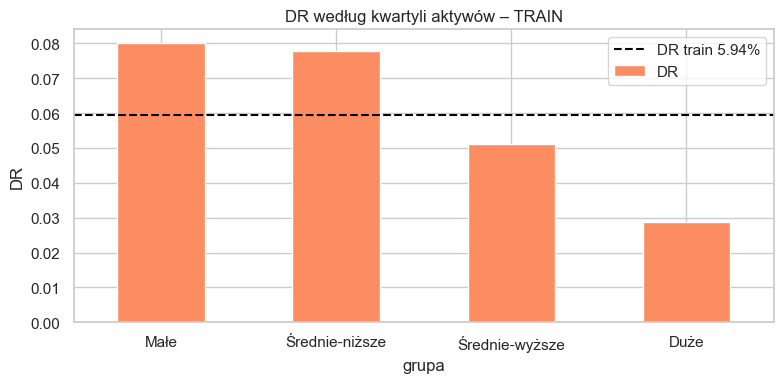

Granice kwartyli aktywów (TRAIN): [      -inf   80629.61  585499.93 2688557.74        inf]


In [39]:
asset = Xtr_raw["Aktywa"].astype(float).replace([np.inf, -np.inf], np.nan)
q_assets = asset.quantile([0.25, 0.50, 0.75]).to_numpy(dtype=float)
AKT_EDGES = np.r_[-np.inf, np.unique(q_assets), np.inf]
AKT_LABELS = (["Małe", "Średnie-niższe", "Średnie-wyższe", "Duże"] if len(AKT_EDGES) == 5
              else [f"Grupa {i+1}" for i in range(len(AKT_EDGES) - 1)])
grupy_aktywa = (pd.DataFrame({"grupa": pd.cut(asset, bins=AKT_EDGES, labels=AKT_LABELS, include_lowest=True), "y": ytr})
                .groupby("grupa", observed=True)["y"].agg(["count", "sum", "mean"])
                .rename(columns={"count": "n", "sum": "defaulty", "mean": "DR"}))
grupy_aktywa["CI"] = [f"[{a:.3f}; {b:.3f}]" for a, b in (wilson(k, n_) for k, n_ in zip(grupy_aktywa["defaulty"], grupy_aktywa["n"]))]
assert int(grupy_aktywa["n"].sum()) == int(asset.notna().sum())
display(grupy_aktywa.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
grupy_aktywa["DR"].plot.bar(ax=ax, color="#fc8d62")
ax.axhline(ytr.mean(), color="black", ls="--", label=f"DR train {ytr.mean():.2%}")
ax.set(ylabel="DR", title="DR według kwartyli aktywów – TRAIN"); ax.legend(); plt.xticks(rotation=0)
savefig("eda_dr_aktywa")
plt.show()
print("Granice kwartyli aktywów (TRAIN):", np.round(AKT_EDGES, 2))

### 7.7. Podsumowanie EDA

In [40]:
print(f"Train: n = {len(ytr)}, defaulty = {int(ytr.sum())}, DR = {ytr.mean():.2%}; "
      f"kotwica PD = {TARGET_PD:.0%} (różnica {100 * (ytr.mean() - TARGET_PD):+.2f} p.p.).")

top5 = (uni[~uni["usuwana (braki)"]].dropna(subset=["AUC"])
        .sort_values("siła AUC", ascending=False).head(5))
print("Top 5 cech według siły jednowymiarowego AUC (TRAIN, bez cech usuwanych z powodu braków):")
display(top5[["AUC", "siła AUC", "kierunek", "IV", "NaN (%)"]].round(4))

print(f"Redundancja: {len(strong_pairs)} par wskaźników o |ρ| > 0,90 "
      f"(w tym {int((strong_pairs.abs() > 0.9999).sum())} par praktycznie identycznych).")
if "vif_data" in globals() and vif_data["VIF"].notna().any():
    print(f"Diagnostyczny VIF > 10: {int((vif_data['VIF'] > 10).sum())} wskaźników.")

if len(grupy_aktywa) >= 2:
    print(f"DR wg aktywów: najmniejsze firmy {grupy_aktywa['DR'].iloc[0]:.2%} "
          f"vs największe {grupy_aktywa['DR'].iloc[-1]:.2%}.")

n_inf = int(np.isposinf(Xtr_raw["wsk_plynnosc_biez_1"]).sum())
print(f"Wartości specjalne: {n_inf} firm ({n_inf / len(Xtr_raw):.1%}) bez zobowiązań krótkoterminowych "
      f"(wsk_plynnosc_biez_1 = +inf).")

Train: n = 1800, defaulty = 107, DR = 5.94%; kotwica PD = 4% (różnica +1.94 p.p.).
Top 5 cech według siły jednowymiarowego AUC (TRAIN, bez cech usuwanych z powodu braków):


,AUC,siła AUC,kierunek,IV,NaN (%)
wsk_index_nowe,0.6983,0.6983,↑ ryzyko,0.5542,0.0000
wsk_index_skr_zaw,0.6673,0.6673,↑ ryzyko,0.4283,0.0000
slog_Kapital_wlasny,0.3367,0.6633,↓ ryzyko,0.3589,0.0000
slog_zysk_brutto,0.3638,0.6362,↓ ryzyko,0.2610,0.0000
wsk_poziom_kapitalu_obrotowego_netto,0.3672,0.6328,↓ ryzyko,0.2668,0.0000


Redundancja: 203 par wskaźników o |ρ| > 0,90 (w tym 19 par praktycznie identycznych).
Diagnostyczny VIF > 10: 29 wskaźników.
DR wg aktywów: najmniejsze firmy 8.00% vs największe 2.89%.
Wartości specjalne: 529 firm (29.4%) bez zobowiązań krótkoterminowych (wsk_plynnosc_biez_1 = +inf).


## 8. Przygotowanie cech

Obie ścieżki korzystają z `ScoringFeatureBuilder` dopasowanego na train; parametry pochodzą z konfiguracji (rozdział 0).

| | `mode="woe"` – model interpretowalny | `mode="blackbox"` |
|---|---|---|
| Kandydaci | wskaźniki `wsk_*` + `log_aktywa` + 4 kategorie | wskaźniki + `slog_*` pozycji kwotowych + 4 kategorie |
| Czyszczenie | usunięcie cech z nadmiarem braków, quasi-stałych i duplikatów | to samo |
| Wartości odstające | binning kwantylowy | capping do [p01, p99] z train |
| Braki i `±inf` | osobne przedziały `BRAK` / `+INF` / `-INF` | mediana / granica cappingu + flagi `__isna` / `__inf` |
| Transformacja | binning monotoniczny + WoE | brak; `scale=True` dla SVM / sieci |
| Kategorie | rzadkie → `INNE`, potem WoE | rzadkie → `INNE`, potem one-hot |
| Selekcja | IV ≥ próg, korelacja WoE < próg, limit liczby cech | brak |

In [41]:
COMMON = dict(cat_cols=CAT_COLS, min_cat_share=MIN_CAT_SHARE, **CLEAN)
FB_PARAMS_WOE = dict(num_cols=NUM_INTERP, mode="woe", **COMMON,
                     **{k: BIN[k] for k in ("max_bins", "min_bin_frac", "smoothing",
                                            "iv_min", "corr_max", "max_features")})
FB_PARAMS_BB = dict(num_cols=NUM_BLACK, mode="blackbox", scale=False, **COMMON)

# dopasowanie na CAŁYM zbiorze treningowym (do dalszych notebooków); w CV fit powtarzany w każdym foldzie
Xg_train = X_git.iloc[idx_train]
fb_woe = ScoringFeatureBuilder(**FB_PARAMS_WOE).fit(Xg_train, y_all[idx_train])
fb_bb  = ScoringFeatureBuilder(**FB_PARAMS_BB).fit(Xg_train, y_all[idx_train])

print("Usunięte (za dużo braków):", fb_bb.cleaner_.dropped_["za_duzo_brakow"])
print("Usunięte (quasi-stałe):   ", fb_bb.cleaner_.dropped_["quasi_stale"][:8], "...")
print("Usunięte (duplikaty):     ", fb_bb.cleaner_.dropped_["duplikat"])
print(f"Cechy po transformacji: WoE = {len(fb_woe.feature_names_)}, black-box = {len(fb_bb.feature_names_)}")

iv = fb_woe.iv_table_
wybrane = iv[iv["status"] == "wybrana"]
# status odrzuconych zawiera powód, np. "korelacja z X (|r| = 0.85)" – grupujemy po rodzaju decyzji
print("Statusy cech:", iv["status"].str.split(" \\(").str[0].value_counts().to_dict())
print("Cechy wybrane z niemonotoniczną relacją WoE (powinno być 0):",
      int((wybrane["monotoniczna"] == False).sum()))

Usunięte (za dużo braków): ['wsk_akt_generowania_got_2', 'wsk_pokrycie_wyd_fin_gotowkowe_2', 'wsk_pokrycie_zob_kr_gotowkowe_2', 'wsk_zadluzenia_gotowki_2', 'wsk_zysk_CF_operacyjny', 'slog_RP_przeplywy_operacyjne', 'slog_RP_amortyzacja']
Usunięte (quasi-stałe):    ['slog_Wartosc_firmy', 'slog_Naleznosci_dostaw_uslug_pow12m_powiazane', 'slog_Naleznosci_dostaw_uslug_pow12m_kapitale', 'slog_Pozostale_rezerwy', 'slog_Zobowiazania_dostaw_uslug_pow12m_powiazane', 'slog_Zobowiazania_dostaw_uslug_12m_kapitale', 'slog_Zobowiazania_dostaw_uslug_pow12m_kapitale', 'slog_Ujemna_wartosc_firmy'] ...
Usunięte (duplikaty):      ['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1', 'slog_Aktywa']
Cechy po transformacji: WoE = 8, black-box = 212
Statusy cech: {'limit liczby cech': 100, 'korelacja z wsk_struktury_k

### 8.1. Tabela IV i selekcja cech karty

In [42]:
assert len(fb_woe.feature_names_) <= BIN["max_features"]
wybrane = iv[iv["status"] == "wybrana"]
display(wybrane.round(4))
assert wybrane["monotoniczna"].fillna(True).astype(bool).all(), "Wybrana cecha liczbowa z niemonotonicznym WoE."
print("Najsilniejsze cechy odrzucone (z powodem):")
display(iv[iv["status"] != "wybrana"].head(12).round(4))
print(f"Cechy z IV > {IV_SUSPICIOUS} (do weryfikacji – rozdz. 5.4 i 9.3):",
      iv[iv["IV"] > IV_SUSPICIOUS].index.tolist())

,IV,ocena_IV,n_binow,monotoniczna,kierunek_ryzyka,status
wsk_index_nowe,0.5542,podejrzanie silna – sprawdź przeciek,5,True,inc,wybrana
wsk_index_skr_zaw,0.4283,silna,5,True,inc,wybrana
wsk_struktury_kapitalu,0.3111,silna,5,True,dec,wybrana
wsk_ebit,0.2783,średnia,5,True,dec,wybrana
wsk_efekt_dzwigni_fin_1,0.2780,średnia,3,True,inc,wybrana
wsk_poziom_kapitalu_obrotowego_netto,0.2668,średnia,5,True,dec,wybrana
wsk_ebitda_3,0.2503,średnia,5,True,dec,wybrana
wsk_stopa_zysku_sprzedaz,0.2253,średnia,5,True,dec,wybrana


Najsilniejsze cechy odrzucone (z powodem):


,IV,ocena_IV,n_binow,monotoniczna,kierunek_ryzyka,status
wsk_struktura_kap_obcego_s,0.3048,silna,5,True,inc,korelacja z wsk_struktury_kapitalu (|r| = 0.80)
wsk_zadluzenie_kap_wlasnego,0.2959,średnia,5,True,inc,korelacja z wsk_struktury_kapitalu (|r| = 0.83)
wsk_zadluzenia,0.2959,średnia,5,True,inc,korelacja z wsk_struktury_kapitalu (|r| = 0.83)
wsk_struktura_kap_wlasnego_s_2,0.2954,średnia,6,True,dec,korelacja z wsk_struktury_kapitalu (|r| = 0.85)
wsk_ogolnego_zadluzenia_1,0.2928,średnia,5,True,inc,korelacja z wsk_struktury_kapitalu (|r| = 0.82)
wsk_struktura_kap_wlasnego_s_1,0.2926,średnia,5,True,dec,korelacja z wsk_struktury_kapitalu (|r| = 0.96)
wsk_ogolnego_zadluzenia_2,0.2924,średnia,5,True,inc,korelacja z wsk_struktury_kapitalu (|r| = 0.87)
wsk_mnoznik_kap_wl,0.2924,średnia,5,True,inc,korelacja z wsk_struktury_kapitalu (|r| = 0.87)
wsk_kapital_do_aktywa,0.2921,średnia,5,True,dec,korelacja z wsk_struktury_kapitalu (|r| = 0.91)
wsk_struktura_kap_wlasnego_2,0.2890,średnia,5,True,dec,korelacja z wsk_struktury_kapitalu (|r| = 0.99)


Cechy z IV > 0.5 (do weryfikacji – rozdz. 5.4 i 9.3): ['wsk_index_nowe']


### 8.2. Profile binów wybranych cech

Słupki – DR w przedziale, linia – WoE (WoE > 0 oznacza ryzyko niższe od średniego). Przedziały specjalne (`BRAK`, `+INF`) są oznaczone na szaro.

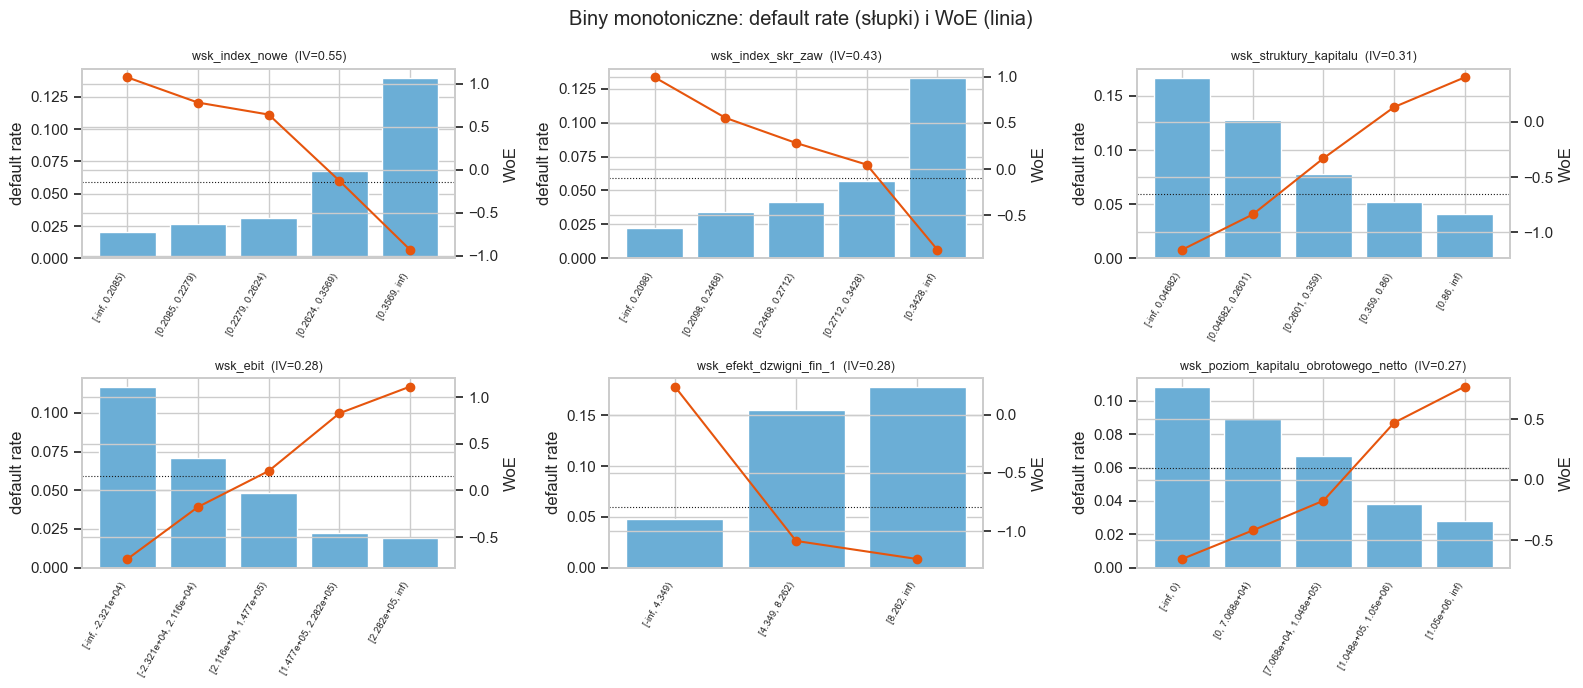

,przedzial,n,defaulty,DR,% dobrych,% złych,WoE,IV,uwaga
0,"[-inf, 0.2085)",438,9,0.0205,0.2534,0.0841,1.0715,0.1785,
1,"[0.2085, 0.2279)",190,5,0.0263,0.1093,0.0467,0.7785,0.0461,
2,"[0.2279, 0.2624)",348,11,0.0316,0.1991,0.1028,0.6394,0.0601,
3,"[0.2624, 0.3569)",459,31,0.0675,0.2528,0.2897,-0.1295,0.0045,
4,"[0.3569, inf)",365,51,0.1397,0.1855,0.4766,-0.9304,0.2650,


In [43]:
sel = iv[iv["status"] == "wybrana"].index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.ravel(), sel):
    p = fb_woe.encoder_.profile(c)
    kol = ["#bdbdbd" if u.startswith(("wartość", "za mało")) else "#6baed6" for u in p["uwaga"]]
    ax.bar(range(len(p)), p["DR"], color=kol)
    ax.set_xticks(range(len(p))); ax.set_xticklabels(p["przedzial"], rotation=60, ha="right", fontsize=7)
    ax.axhline(y_all[idx_train].mean(), color="k", ls=":", lw=.8); ax.set_ylabel("default rate")
    ax2 = ax.twinx(); ax2.plot(range(len(p)), p["WoE"], "o-", color="#e6550d"); ax2.set_ylabel("WoE")
    ax.set_title(f"{c}  (IV={iv.loc[c, 'IV']:.2f})", fontsize=9)
for ax in axes.ravel()[len(sel):]:
    ax.axis("off")
plt.suptitle("Biny monotoniczne: default rate (słupki) i WoE (linia)")
savefig("woe_profiles")
plt.show()
display(fb_woe.encoder_.profile(sel[0]).round(4))

### 8.3. Kierunki zależności

Oczekiwany kierunek wpływu cechy na ryzyko jest określony z góry na podstawie znaczenia wskaźnika (Lab 3) i porównany z kierunkiem z binningu oraz znakiem korelacji Spearmana.

In [44]:
sel = wybrane.index.tolist()      # wszystkie cechy karty (używane też w 9.4 i 10)

OCZEKIWANIA = [   # (fragment nazwy, oczekiwany kierunek ryzyka, uzasadnienie); sprawdzane w tej kolejności
    ("index_skr_zaw", "inc", "więcej wykreśleń/zawieszeń firm w branży -> gorsze otoczenie"),
    ("index_nowe", "?", "napływ nowych firm: konkurencja (↑) albo dobra koniunktura (↓)"),
    ("index_aktywne", "?", "zmiana liczby aktywnych firm: kierunek niejednoznaczny"),
    ("ebit", "dec", "wyższy wynik operacyjny / EBITDA (także względem zobowiązań i odsetek) -> niższe ryzyko"),
    ("zysk", "dec", "wyższy zysk (także względem zobowiązań i odsetek) -> niższe ryzyko"),
    ("rent", "dec", "wyższa rentowność -> niższe ryzyko"),
    ("ROE", "dec", "wyższa rentowność kapitału -> niższe ryzyko"),
    ("ROA", "dec", "wyższa rentowność aktywów -> niższe ryzyko"),
    ("ROS", "dec", "wyższa rentowność sprzedaży -> niższe ryzyko"),
    ("marza", "dec", "wyższa marża -> niższe ryzyko"),
    ("pokryc", "dec", "lepsze pokrycie zobowiązań / aktywów / odsetek -> niższe ryzyko"),
    ("zadluz", "inc", "wyższe zadłużenie -> wyższe ryzyko"),
    ("kap_obc", "inc", "większy udział kapitału obcego -> wyższe ryzyko"),
    ("kapitalu_obcego", "inc", "większy udział kapitału obcego -> wyższe ryzyko"),
    ("mnoznik_kap", "inc", "aktywa / kapitał własny – dźwignia"),
    ("dzwigni", "?", "efekt dźwigni: znak zależy od relacji ROA do kosztu długu"),
    ("zob", "inc", "wyższe zobowiązania względem aktywów / przychodów -> wyższe ryzyko"),
    ("koszty", "inc", "wyższe koszty względem przychodów -> niższa marża"),
    ("odsetk", "inc", "wyższe obciążenie odsetkami -> wyższe ryzyko"),
    ("kapitalu_obrotowego", "dec", "większy kapitał obrotowy netto -> bufor płynności"),
    ("plynnosc", "dec", "wyższa płynność -> niższe ryzyko"),
    ("kap_wlasn", "dec", "większy udział kapitału własnego -> niższe ryzyko"),
    ("kapital_do_aktywa", "dec", "większy udział kapitału własnego -> niższe ryzyko"),
    ("got", "dec", "więcej gotówki / przepływów -> niższe ryzyko"),
    ("dni_istnienia", "dec", "starsze firmy -> niższe ryzyko"),
    ("log_aktywa", "dec", "większe firmy -> niższe ryzyko"),
]

def oczekiwany(nazwa):
    for frag, kier, uzas in OCZEKIWANIA:
        if frag.lower() in nazwa.lower():
            return kier, uzas
    return "?", "brak jednoznacznej hipotezy – wymaga interpretacji"

# Komentarz do kierunku każdej cechy karty (opis zależności w danych, nie przyczynowości).
OCENY_EKONOMICZNE = {
    "wsk_index_skr_zaw": "Zgodny z oczekiwaniem: wyższy udział wykreśleń i zawieszeń w branży – wyższe ryzyko. "
                         "Okres pomiaru do potwierdzenia (5.4).",
    "wsk_index_nowe": "Brak hipotezy a priori; w danych wyższa wartość – wyższe ryzyko. Okres pomiaru do potwierdzenia (5.4).",
    "wsk_struktury_kapitalu": "Brak hipotezy a priori; w danych wyższa wartość – niższe ryzyko. Wzór do potwierdzenia w opisie zmiennych.",
    "wsk_ebit": "Zgodny z oczekiwaniem: wyższy wynik operacyjny – niższe ryzyko.",
    "wsk_efekt_dzwigni_fin_1": "Brak hipotezy a priori; w danych wyższa wartość – wyższe ryzyko. Wzór do potwierdzenia w opisie zmiennych.",
    "wsk_poziom_kapitalu_obrotowego_netto": "Zgodny z oczekiwaniem: wyższy kapitał obrotowy netto – niższe ryzyko.",
    "wsk_ebitda_3": "Zgodny z oczekiwaniem: wyższa EBITDA – niższe ryzyko.",
    "wsk_stopa_zysku_sprzedaz": "Zgodny z oczekiwaniem: wyższa marża zysku na sprzedaży – niższe ryzyko.",
}

KIER = {"inc": "↑ ryzyko", "dec": "↓ ryzyko", "?": "?", "n/d": "kategoria"}
rows = []
for c in sel:
    k_bin = iv.loc[c, "kierunek_ryzyka"]
    kategoria = c in CAT_COLS
    k_exp, uzas = ("n/d", "zmienna kategoryczna – WoE poziomów") if kategoria else oczekiwany(c)
    rho = np.nan if kategoria else safe_spearman(Xtr_feat[c], ytr)

    # (1) właściwy test: oczekiwanie a priori vs kierunek z binningu
    zg_apriori = "n/d" if kategoria else ("brak hipotezy" if k_exp == "?" else ("TAK" if k_exp == k_bin else "NIE"))
    # (2) kontrola spójności: znak Spearmana vs kierunek z binningu (oba z danych)
    if kategoria or pd.isna(rho) or k_bin not in ("inc", "dec"):
        zg_spearman = "n/d"
    elif abs(rho) < 1e-10:
        zg_spearman = "brak kierunku"
    else:
        zg_spearman = "TAK" if (rho > 0) == (k_bin == "inc") else "NIE"

    rows.append({"cecha": c, "IV": iv.loc[c, "IV"],
                 "oczekiwany (a priori)": KIER[k_exp], "z binningu": KIER.get(k_bin, k_bin),
                 "zgodność a priori": zg_apriori,
                 "Spearman z default": rho, "znak Spearmana zgodny": zg_spearman,
                 "uzasadnienie a priori": uzas,
                 "ocena ekonomiczna": OCENY_EKONOMICZNE.get(c, "Wymaga indywidualnej interpretacji ekonomicznej.")})

kierunki = pd.DataFrame(rows).set_index("cecha")
assert len(kierunki) == len(wybrane), "Tabela kierunków nie obejmuje wszystkich cech karty."
display(kierunki.round(4))
print("Niezgodne z oczekiwaniem a priori:", kierunki.index[kierunki["zgodność a priori"] == "NIE"].tolist() or "brak")
print("Bez hipotezy a priori (wymagają interpretacji):",
      kierunki.index[kierunki["zgodność a priori"] == "brak hipotezy"].tolist() or "brak")
print("Niespójny znak Spearmana:", kierunki.index[kierunki["znak Spearmana zgodny"] == "NIE"].tolist() or "brak")
print("Zgodność kierunku z oczekiwaniem nie oznacza zależności przyczynowej.")

,IV,oczekiwany (a priori),z binningu,zgodność a priori,Spearman z default,znak Spearmana zgodny,uzasadnienie a priori,ocena ekonomiczna
cecha,,,,,,,,
wsk_index_nowe,0.5542,?,↑ ryzyko,brak hipotezy,0.1624,TAK,napływ nowych firm: konkurencja (↑) albo dobra...,Brak hipotezy a priori; w danych wyższa wartoś...
wsk_index_skr_zaw,0.4283,↑ ryzyko,↑ ryzyko,TAK,0.1370,TAK,więcej wykreśleń/zawieszeń firm w branży -> go...,Zgodny z oczekiwaniem: wyższy udział wykreśleń...
wsk_struktury_kapitalu,0.3111,?,↓ ryzyko,brak hipotezy,-0.1000,TAK,brak jednoznacznej hipotezy – wymaga interpret...,Brak hipotezy a priori; w danych wyższa wartoś...
wsk_ebit,0.2783,↓ ryzyko,↓ ryzyko,TAK,-0.1051,TAK,wyższy wynik operacyjny / EBITDA (także względ...,Zgodny z oczekiwaniem: wyższy wynik operacyjny...
wsk_efekt_dzwigni_fin_1,0.2780,?,↑ ryzyko,brak hipotezy,0.0342,TAK,efekt dźwigni: znak zależy od relacji ROA do k...,Brak hipotezy a priori; w danych wyższa wartoś...
wsk_poziom_kapitalu_obrotowego_netto,0.2668,↓ ryzyko,↓ ryzyko,TAK,-0.1088,TAK,większy kapitał obrotowy netto -> bufor płynności,Zgodny z oczekiwaniem: wyższy kapitał obrotowy...
wsk_ebitda_3,0.2503,↓ ryzyko,↓ ryzyko,TAK,-0.0988,TAK,wyższy wynik operacyjny / EBITDA (także względ...,Zgodny z oczekiwaniem: wyższa EBITDA – niższe ...
wsk_stopa_zysku_sprzedaz,0.2253,↓ ryzyko,↓ ryzyko,TAK,-0.0954,TAK,wyższy zysk (także względem zobowiązań i odset...,Zgodny z oczekiwaniem: wyższa marża zysku na s...


Niezgodne z oczekiwaniem a priori: brak
Bez hipotezy a priori (wymagają interpretacji): ['wsk_index_nowe', 'wsk_struktury_kapitalu', 'wsk_efekt_dzwigni_fin_1']
Niespójny znak Spearmana: brak
Zgodność kierunku z oczekiwaniem nie oznacza zależności przyczynowej.


**Wniosek.** Wszystkie 5 cech z określonym oczekiwanym kierunkiem ma kierunek zgodny z oczekiwaniem, a znak korelacji Spearmana jest zgodny z binningiem dla wszystkich 8 cech. Dla `wsk_index_nowe`, `wsk_struktury_kapitalu` i `wsk_efekt_dzwigni_fin_1` kierunku nie określono z góry – ich interpretację należy potwierdzić w opisie zmiennych. W regresji logistycznej na WoE oczekujemy ujemnych współczynników β.

### 8.4. Współliniowość cech karty

Korelacje między cechami WoE karty, VIF oraz liczba defaultów na parametr (EPV).

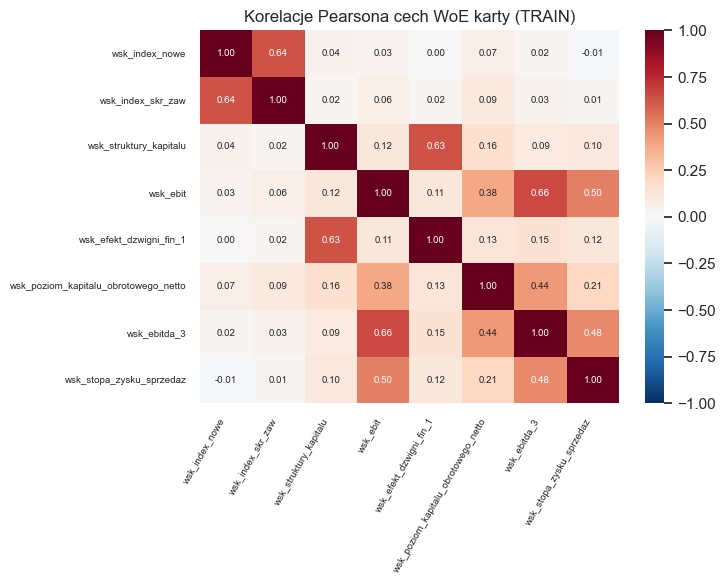

,VIF
wsk_ebitda_3,2.0400
wsk_ebit,1.9700
wsk_struktury_kapitalu,1.7100
wsk_efekt_dzwigni_fin_1,1.7100
wsk_index_skr_zaw,1.7000
wsk_index_nowe,1.6900
wsk_stopa_zysku_sprzedaz,1.4200
wsk_poziom_kapitalu_obrotowego_netto,1.2900


Maks. |r| między cechami karty: 0.66 (próg 0.7); maks. VIF: 2.04 (praktyczny próg 5).
Zdarzeń na parametr karty (EPV): 11.9 = 107 defaultów / 9 parametrów.


In [45]:
Z_tr = fb_woe.transform(Xg_train)
Rw = Z_tr.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(Rw, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_xticklabels([c.replace("woe__", "") for c in Rw.columns], rotation=60, ha="right", fontsize=7)
ax.set_yticklabels([c.replace("woe__", "") for c in Rw.index], fontsize=7)
ax.set_title("Korelacje Pearsona cech WoE karty (TRAIN)")
savefig("woe_corr")
plt.show()
vif_woe = pd.Series(np.diag(np.linalg.inv(Rw.to_numpy())), index=[c.replace("woe__", "") for c in Rw.columns],
                    name="VIF").sort_values(ascending=False)
display(vif_woe.to_frame().round(2))
print(f"Maks. |r| między cechami karty: {Rw.where(~np.eye(len(Rw), dtype=bool)).abs().max().max():.2f} "
      f"(próg {BIN['corr_max']}); maks. VIF: {vif_woe.max():.2f} (praktyczny próg 5).")
epv = int(y_all[idx_train].sum()) / (len(fb_woe.feature_names_) + 1)
print(f"Zdarzeń na parametr karty (EPV): {epv:.1f} = {int(y_all[idx_train].sum())} defaultów / "
      f"{len(fb_woe.feature_names_) + 1} parametrów.")

### 8.5. Transformacja zbiorów

Validation i test są przekształcane wyłącznie przez `transform()` transformerów dopasowanych na train. Sprawdzamy brak `NaN` / `inf`, zgodność kolumn oraz to, że wartości WoE pochodzą z train.

In [46]:
X_sets = {}
for name, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    Xi = X_git.iloc[idx]
    X_sets[name] = {"woe": fb_woe.transform(Xi), "bb": fb_bb.transform(Xi)}
    for kind in ("woe", "bb"):
        Z = X_sets[name][kind]
        assert Z.index.equals(Xi.index) and np.isfinite(Z.to_numpy(dtype=float)).all(), f"{name}/{kind}: NaN lub inf"
    assert list(X_sets[name]["woe"].columns) == fb_woe.feature_names_
    assert list(X_sets[name]["bb"].columns) == fb_bb.feature_names_
for c in fb_woe.feature_names_:
    learned = set(np.round(X_sets["train"]["woe"][c], 10)) | {0.0}
    for name in ("val", "test"):
        assert set(np.round(X_sets[name]["woe"][c], 10)) <= learned, f"{c}: WoE spoza wartości z train ({name})"
print({k: (v["woe"].shape, v["bb"].shape) for k, v in X_sets.items()})
display(X_sets["train"]["woe"].describe().T.round(4))

{'train': ((1800, 8), (1800, 212)), 'val': ((600, 8), (600, 212)), 'test': ((600, 8), (600, 212))}


,count,mean,std,min,25%,50%,75%,max
woe__wsk_index_nowe,"1,800.0000",0.2448,0.7366,-0.9304,-0.1295,0.6394,0.7785,1.0715
woe__wsk_index_skr_zaw,"1,800.0000",0.1869,0.6447,-0.8736,0.0489,0.0489,0.5560,0.9945
woe__wsk_struktury_kapitalu,"1,800.0000",0.1232,0.4848,-1.1565,0.1332,0.4019,0.4019,0.4019
woe__wsk_ebit,"1,800.0000",0.1331,0.5838,-0.7358,-0.1772,-0.1772,0.3631,1.1132
woe__wsk_efekt_dzwigni_fin_1,"1,800.0000",0.1025,0.4227,-1.2410,0.2431,0.2431,0.2431,0.2431
woe__wsk_poziom_kapitalu_obrotowego_netto,"1,800.0000",0.1203,0.5246,-0.6568,-0.4205,0.4692,0.4692,0.7682
woe__wsk_ebitda_3,"1,800.0000",0.1148,0.5203,-0.6819,-0.3682,0.0702,0.7600,0.7600
woe__wsk_stopa_zysku_sprzedaz,"1,800.0000",0.0997,0.4732,-0.5277,-0.4621,0.1231,0.6010,0.6010


## 9. Test poprawności pipeline'u (wymaganie 3.1)

W każdym foldzie cały pipeline (czyszczenie → binning/WoE → selekcja → model) jest dopasowywany od nowa na części treningowej foldu. Modele kontrolne: `LogisticRegression(C=0.1)` na cechach WoE i `HistGradientBoostingClassifier`. Nie są to modele finalne – służą do sprawdzenia przygotowania cech.

In [47]:
def run_cv(params, model_factory, folds_glob, y, label, X=X_git):
    res = []
    test_rows = set(idx_test)
    for k, (tr, va) in enumerate(folds_glob, 1):
        assert test_rows.isdisjoint(tr) and test_rows.isdisjoint(va), "Wiersz testu w CV!"
        fb = ScoringFeatureBuilder(**params).fit(X.iloc[tr], y[tr])        # fit TYLKO na foldzie treningowym
        Z_tr, Z_va = fb.transform(X.iloc[tr]), fb.transform(X.iloc[va])
        m = model_factory().fit(Z_tr, y[tr])
        res.append(dict(model=label, fold=k, AUC_uczenie=roc_auc_score(y[tr], m.predict_proba(Z_tr)[:, 1]),
                        AUC=roc_auc_score(y[va], m.predict_proba(Z_va)[:, 1]), n_cech=len(fb.feature_names_),
                        cechy=tuple(fb.feature_names_)))
    return pd.DataFrame(res)

lr = lambda: LogisticRegression(C=0.1, max_iter=2000)
hgb = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                             min_samples_leaf=40, random_state=RNG_SEED)

def podsumuj(df_cv):
    g = df_cv.groupby("model")
    out = g.agg(AUC_srednia=("AUC", "mean"), AUC_std=("AUC", "std"), AUC_min=("AUC", "min"), AUC_max=("AUC", "max"),
                AUC_uczenie=("AUC_uczenie", "mean"), n_cech=("n_cech", "mean"))
    out["Gini_srednia"] = 2 * out["AUC_srednia"] - 1
    out["luka uczenie-walidacja"] = out["AUC_uczenie"] - out["AUC_srednia"]
    return out

### 9.1. Powtarzane CV na train

In [48]:
cv_res = pd.concat([run_cv(FB_PARAMS_WOE, lr, cv_train_rep_glob, y_all, "karta: WoE + regresja logistyczna"),
                    run_cv(FB_PARAMS_BB, hgb, cv_train_rep_glob, y_all, "black-box: przygotowanie + HGB")])
cv_summary = podsumuj(cv_res)
print(f"Stratified {N_FOLDS}-fold CV × {N_REPEATS} powtórzenia na TRAIN:")
display(cv_summary.round(4))

Stratified 5-fold CV × 3 powtórzenia na TRAIN:


,AUC_srednia,AUC_std,AUC_min,AUC_max,AUC_uczenie,n_cech,Gini_srednia,luka uczenie-walidacja
model,,,,,,,,
black-box: przygotowanie + HGB,0.7103,0.0411,0.6435,0.7929,0.9900,212.1333,0.4206,0.2797
karta: WoE + regresja logistyczna,0.7202,0.0491,0.6103,0.7825,0.8000,8.0000,0.4403,0.0798


**Wniosek.** AUC w CV: karta 0,7202 (Gini 0,4403), HGB 0,7103 (Gini 0,4206); różnica jest mniejsza niż odchylenie między foldami (0,03–0,05). HGB ma AUC na danych uczących 0,99, co wskazuje na przeuczenie – w notebooku modelowym wymaga regularyzacji. Luka uczenie–walidacja karty wynosi 0,08.

### 9.2. Test permutacji etykiet

Po losowym przetasowaniu `default` w train cały pipeline jest uczony od nowa. Jeśli transformacje i selekcja nie korzystają z danych walidacyjnych, AUC powinno wynosić około 0,5.

In [49]:
N_PERM = 10
perm_rows = []
for r in range(N_PERM):
    y_perm = y_all.copy()
    y_perm[idx_train] = np.random.default_rng(RNG_SEED + r).permutation(y_all[idx_train])
    for params, factory, label in [(FB_PARAMS_WOE, lr, "karta"), (FB_PARAMS_BB, hgb, "black-box")]:
        perm_rows.append({"model": label, "permutacja": r,
                          "AUC": run_cv(params, factory, cv_train_glob, y_perm, label)["AUC"].mean()})
perm = pd.DataFrame(perm_rows)
perm_summary = perm.groupby("model")["AUC"].agg(["mean", "std", "min", "max"])
display(perm_summary.round(3))
for model, row in perm_summary.iterrows():
    z = (row["mean"] - 0.5) / (row["std"] / np.sqrt(N_PERM))
    print(f"{model}: średnie AUC po permutacji = {row['mean']:.3f} (test t względem 0,5: z = {z:+.2f})")
assert (perm_summary["mean"] < 0.56).all(), "AUC po permutacji wyraźnie > 0,5 – podejrzenie przecieku!"
print("OK: brak sygnału przecieku – po permutacji etykiet pipeline nie odtwarza informacji o targecie.")

,mean,std,min,max
model,,,,
black-box,0.5180,0.0350,0.4600,0.5640
karta,0.5150,0.0340,0.4660,0.5670


black-box: średnie AUC po permutacji = 0.518 (test t względem 0,5: z = +1.57)
karta: średnie AUC po permutacji = 0.515 (test t względem 0,5: z = +1.41)
OK: brak sygnału przecieku – po permutacji etykiet pipeline nie odtwarza informacji o targecie.


**Wniosek.** Średnie AUC po permutacji: 0,515 (karta) i 0,518 (black-box), maksimum 0,57. Wyniki są bliskie 0,5 i znacznie niższe niż na prawdziwych etykietach (0,71–0,72), co nie wskazuje na przeciek danych. Dla black-boxa z = 1,93 jest blisko progu istotności 1,96.

### 9.3. Test wrażliwości na `wsk_index_*`

Na tych samych foldach porównujemy modele z `wsk_index_*` i bez nich; różnice liczone są fold do foldu.

In [50]:
def bez_index(params):
    p = dict(params); p["num_cols"] = [c for c in params["num_cols"] if c not in SUSPICIOUS]
    return p

base_woe = FB_PARAMS_WOE if not DROP_SUSPICIOUS else dict(FB_PARAMS_WOE, num_cols=FB_PARAMS_WOE["num_cols"] + SUSPICIOUS)
base_bb = FB_PARAMS_BB if not DROP_SUSPICIOUS else dict(FB_PARAMS_BB, num_cols=FB_PARAMS_BB["num_cols"] + SUSPICIOUS)
wr = []
for label, params, factory in [("karta", base_woe, lr), ("black-box", base_bb, hgb)]:
    a = run_cv(params, factory, cv_train_rep_glob, y_all, label)["AUC"].to_numpy()
    b = run_cv(bez_index(params), factory, cv_train_rep_glob, y_all, label)["AUC"].to_numpy()
    d = a - b
    wr.append({"model": label, "AUC z wsk_index_*": a.mean(), "AUC bez wsk_index_*": b.mean(),
               "różnica AUC": d.mean(), "różnica Gini": 2 * d.mean(), "std różnicy (fold)": d.std(ddof=1),
               "foldy z poprawą": f"{int((d > 0).sum())}/{len(d)}"})
wrazliwosc = pd.DataFrame(wr).set_index("model")
display(wrazliwosc.round(4))

,AUC z wsk_index_*,AUC bez wsk_index_*,różnica AUC,różnica Gini,std różnicy (fold),foldy z poprawą
model,,,,,,
karta,0.7202,0.6588,0.0614,0.1228,0.0552,12/15
black-box,0.7103,0.6350,0.0753,0.1506,0.0519,14/15


**Wniosek.** Bez `wsk_index_*` AUC karty spada o 0,06 (w 12 z 15 foldów), a black-boxa o 0,08 (w 14 z 15 foldów). Bez tych wskaźników Gini wynosi 0,32 (karta) i 0,27 (black-box), więc pozostałe cechy zachowują istotną moc predykcyjną. Wskaźniki pozostają w modelu (warunek z 5.4); w notebookach modelowych raportujemy także wariant bez nich.

### 9.4. Stabilność selekcji cech karty

Częstość wyboru cech w 15 foldach oraz średni indeks Jaccarda zbiorów wybranych cech – dla pojedynczych wskaźników i dla grup wskaźników (sektor, wynik i rentowność, zadłużenie i struktura kapitału, płynność, sprawność).

In [51]:
sel_sets = [set(f) for f in cv_res.loc[cv_res["model"].str.startswith("karta"), "cechy"]]
n_f = len(sel_sets)
freq = pd.Series([c.replace("woe__", "") for s in sel_sets for c in s]).value_counts()
jac = np.mean([len(a & b) / len(a | b) for i, a in enumerate(sel_sets) for b in sel_sets[i + 1:]])
stab = freq.to_frame("liczba foldów").assign(**{"udział foldów": lambda d: d["liczba foldów"] / n_f,
                                                 "w finalnej karcie": lambda d: d.index.isin(sel)})
display(stab.head(20).round(2))
print(f"Cechy wybrane we wszystkich {n_f} foldach: {int((freq == n_f).sum())}; w >= 80% foldów: "
      f"{int((freq >= 0.8 * n_f).sum())}; w dowolnym foldzie: {len(freq)}.")
print(f"Średni indeks Jaccarda między foldami: {jac:.2f}")
print("Cechy finalnej karty wybierane w < 50% foldów:",
      stab.index[(stab["w finalnej karcie"]) & (stab["udział foldów"] < 0.5)].tolist() or "brak")

RODZINY = [   # (rodzina, fragmenty nazw) – kolejność ma znaczenie
    ("sektor", ("index_",)),
    ("wynik i rentowność", ("ebit", "zysk", "rent", "roe", "roa", "ros", "marza", "pokrycia_odsetek")),
    ("płynność i kapitał obrotowy", ("plynnosc", "kapitalu_obrotowego", "got", "kap_obrotowy")),
    ("zadłużenie i struktura kapitału", ("zadluz", "kap_obc", "kapitalu_obcego", "mnoznik", "kap_wlasn", "kapitalu_wlasnego",
                                         "struktur", "zob", "kapital_do_aktywa", "dzwigni", "fin_majatku", "pokrycie")),
    ("sprawność", ("rotacja", "obrot", "cykl", "sprzedaz")),
]
def rodzina(nazwa):
    n_ = nazwa.lower().replace("woe__", "")
    return next((r for r, frag in RODZINY if any(f in n_ for f in frag)), "inne")
fam_sets = [{rodzina(c) for c in s_} for s_ in sel_sets]
jac_fam = np.mean([len(a & b) / len(a | b) for i, a in enumerate(fam_sets) for b in fam_sets[i + 1:]])
fam_freq = pd.Series([r for s_ in fam_sets for r in s_]).value_counts().div(n_f).rename("udział foldów z rodziną")
display(fam_freq.to_frame().round(2))
print(f"Rodziny w finalnej karcie: {sorted({rodzina(c) for c in sel})}")
print(f"Średni indeks Jaccarda: pojedyncze wskaźniki {jac:.2f} vs rodziny wskaźników {jac_fam:.2f}")

,liczba foldów,udział foldów,w finalnej karcie
wsk_index_nowe,15,1.0000,True
wsk_index_skr_zaw,15,1.0000,True
wsk_ebitda_3,13,0.8700,True
wsk_efekt_dzwigni_fin_1,12,0.8000,True
wsk_ebit,12,0.8000,True
wsk_poziom_kapitalu_obrotowego_netto,11,0.7300,True
wsk_struktury_kapitalu,8,0.5300,True
wsk_rent_kaptial_podstawowy,6,0.4000,False
wsk_stopa_zysku_sprzedaz,5,0.3300,True
wsk_udzial_zapasy_zobowiazania,4,0.2700,False


Cechy wybrane we wszystkich 15 foldach: 2; w >= 80% foldów: 5; w dowolnym foldzie: 25.
Średni indeks Jaccarda między foldami: 0.49
Cechy finalnej karty wybierane w < 50% foldów: ['wsk_stopa_zysku_sprzedaz']


,udział foldów z rodziną
zadłużenie i struktura kapitału,1.0000
sektor,1.0000
wynik i rentowność,0.9300
płynność i kapitał obrotowy,0.7300
inne,0.0700
sprawność,0.0700


Rodziny w finalnej karcie: ['płynność i kapitał obrotowy', 'sektor', 'wynik i rentowność', 'zadłużenie i struktura kapitału']
Średni indeks Jaccarda: pojedyncze wskaźniki 0.49 vs rodziny wskaźników 0.82


**Wniosek.** Oba wskaźniki sektorowe są wybierane w każdym foldzie, a `wsk_ebitda_3`, `wsk_ebit`, `wsk_efekt_dzwigni_fin_1` i kapitał obrotowy netto w 73–87% foldów. Najrzadziej wybieraną cechą finalnej karty jest `wsk_stopa_zysku_sprzedaz` (33% foldów). Jaccard dla pojedynczych wskaźników wynosi 0,49, a dla grup 0,82 – między foldami zmieniają się głównie wskaźniki w obrębie tej samej grupy.

## 10. Zapis wyników

Zapisywane są: podziały i foldy, dopasowane transformery (`feature_builders.joblib`), tabela IV, profile binów, zbiory po transformacji oraz manifest z konfiguracją i sumą kontrolną danych. Do wczytania `feature_builders.joblib` w kolejnym notebooku potrzebne są definicje klas z rozdziału 3.

In [52]:
karta_final = wybrane.index.tolist()
for old in ART_DIR.glob("*.*"):          # usuwamy wyniki poprzednich uruchomień, by katalog odpowiadał temu przebiegowi
    old.unlink()

splits = {
    "seed": RNG_SEED, "split_mode": SPLIT_MODE, "group_split": GROUPS is not None,
    "index_train": X_train.index.tolist(), "index_val": X_valid.index.tolist(), "index_test": X_test.index.tolist(),
    "pos_train": idx_train.tolist(), "pos_val": idx_val.tolist(), "pos_test": idx_test.tolist(),
    "cv_train_local": [{"train": tr.tolist(), "val": va.tolist()} for tr, va in cv_train],
    "cv_train_global": [{"train": tr.tolist(), "val": va.tolist()} for tr, va in cv_train_glob],
    "cv_dev_global": [{"train": tr.tolist(), "val": va.tolist()} for tr, va in cv_dev_glob],
}
with open(ART_DIR / "splits.json", "w", encoding="utf-8") as f:
    json.dump(splits, f)
joblib.dump({"woe": fb_woe, "blackbox": fb_bb}, ART_DIR / "feature_builders.joblib")
iv.to_csv(ART_DIR / "iv_table.csv")
pd.concat({c: fb_woe.encoder_.profile(c) for c in karta_final}).to_csv(ART_DIR / "woe_bins_selected.csv")
dq.to_csv(ART_DIR / "dq_train.csv")
uni.to_csv(ART_DIR / "univariate_train.csv")
for name, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    for kind in ("woe", "bb"):
        X_sets[name][kind].assign(**{TARGET: y_all[idx]}).to_csv(ART_DIR / f"X_{name}_{kind}.csv")

with open(DATA_PATH, "rb") as f:
    data_md5 = hashlib.md5(f.read()).hexdigest()
manifest = {
    "data_file": DATA_PATH, "data_md5": data_md5, "n_obs": len(X_raw), "n_defaults": int(y_raw.sum()),
    "target_pd_anchor": TARGET_PD, "seed": RNG_SEED,
    "split": {"mode": SPLIT_MODE, "train": len(idx_train), "val": len(idx_val), "test": len(idx_test),
              "defaults": {"train": int(y_train.sum()), "val": int(y_valid.sum()), "test": int(y_test.sum())},
              "cv_folds": N_FOLDS, "cv_repeats_check": N_REPEATS},
    "config": {"CLEAN": CLEAN, "BIN": BIN, "MIN_CAT_SHARE": MIN_CAT_SHARE, "IV_SUSPICIOUS": IV_SUSPICIOUS},
    "decisions": {"drop_suspicious_wsk_index": DROP_SUSPICIOUS, "group_split": GROUPS is not None,
                  "woe_convention": "WoE = ln(%good/%bad) (Lab 1); expected beta < 0",
                  "special_values": "WoE: own bins BRAK/+INF/-INF; black-box: cap + __inf / median + __isna"},
    "features_woe": fb_woe.feature_names_, "n_features_blackbox": len(fb_bb.feature_names_),
    "dropped_blackbox": {k: v for k, v in fb_bb.cleaner_.dropped_.items() if k != "duplikat_kolumny"},
    "cv_check": cv_summary[["AUC_srednia", "AUC_std", "AUC_uczenie"]].round(4).to_dict("index"),
    "permutation_auc_mean": perm_summary["mean"].round(4).to_dict(),
    "sensitivity_wsk_index": wrazliwosc[["AUC z wsk_index_*", "AUC bez wsk_index_*", "różnica AUC"]].round(4).to_dict("index"),
    "selection_stability_jaccard": round(float(jac), 3),
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__, "scipy": scipy.__version__},
}
with open(ART_DIR / "feature_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False, default=str)

# kontrola odczytu
chk = json.loads((ART_DIR / "splits.json").read_text(encoding="utf-8"))
assert chk["pos_test"] == idx_test.tolist() and len(chk["cv_train_global"]) == N_FOLDS
re_fb = joblib.load(ART_DIR / "feature_builders.joblib")["woe"]
pd.testing.assert_frame_equal(re_fb.transform(X_git.iloc[idx_val]), X_sets["val"]["woe"])
print("Zapisano:", sorted(p.name for p in ART_DIR.iterdir() if p.is_file()))
print("Wykresy:", sorted(p.name for p in FIG_DIR.iterdir()))

Zapisano: ['X_test_bb.csv', 'X_test_woe.csv', 'X_train_bb.csv', 'X_train_woe.csv', 'X_val_bb.csv', 'X_val_woe.csv', 'dq_train.csv', 'feature_builders.joblib', 'feature_manifest.json', 'iv_table.csv', 'splits.json', 'univariate_train.csv', 'woe_bins_selected.csv']
Wykresy: ['corr_top40.png', 'dq_braki_inf.png', 'eda_corr_top40.png', 'eda_dr_aktywa.png', 'eda_dr_kategorie.png', 'eda_target.png', 'eda_top_features.png', 'schemat_walidacji.png', 'woe_corr.png', 'woe_profiles.png']


## 11. Podsumowanie

| Wymaganie | Realizacja | Rozdział |
|---|---|---|
| Podział stratyfikowany train / validation / test | 60/20/20, stratyfikacja po `default`; DR w zbiorach 5,8–6,0% | 4 |
| Stratified K-fold CV (min. 5 foldów) | 5 foldów na train (+ 5×3 do testów, + `cv_dev`) | 4.1, 9 |
| Podział grupowy przy powtórzeniach podmiotu | powtórzeń nie wykryto; kod obsługuje `StratifiedGroupKFold` | 2.2, 4, 5.2 |
| Dokumentacja schematu walidacji | tabela ról zbiorów i diagram | 4, 4.2 |
| Kontrola data leakage | asercje rozłączności i foldów, brak wspólnych obserwacji, audyt cech, test permutacji, test wrażliwości | 5, 9 |
| Test tylko do oceny końcowej | test nie jest używany w EDA, dopasowaniu ani CV | 4, 5.1, 9 |
| Data Quality | braki, `±inf`, tożsamości bilansowe, wartości niemożliwe, ogony, cechy quasi-stałe, duplikaty | 2, 6 |
| EDA | AUC, IV, rozkłady, DR w kategoriach i grupach wielkości, korelacje, VIF | 7 |
| Binning monotoniczny, WoE / encoding | binning z przedziałami specjalnymi, WoE wg Lab 1, kategorie → `INNE` → WoE / one-hot | 3, 8 |
| Capping, standaryzacja | capping p1–p99 z train (black-box), binning (karta), opcja `scale=True` | 3, 6.4, 8 |
| Transformacje tylko na train / foldach | wszystkie w `fit()`; potwierdza test permutacji | 3, 8.5, 9.2 |

**Decyzje**
1. WoE = ln(%dobrych / %złych) (Lab 1), oczekiwane β < 0.
2. `±inf` i `NaN` obsługiwane jako osobne przedziały WoE / flagi w black-boxie.
3. Karta: 8 cech (IV ≥ 0,02, |r| < 0,70, limit 8 cech – EPV ≈ 12), wszystkie z monotonicznym WoE.
4. `wsk_index_*` pozostają w modelu; wariant bez nich jest raportowany równolegle.

**Do potwierdzenia w opisie zmiennych:** okres pomiaru `wsk_index_*`, definicja defaultu i horyzont.

**Kolejne etapy:** modele na `X_*_woe.csv` i `X_*_bb.csv`; kalibracja na validation (porównanie Platta i regresji izotonicznej, korekta poziomu do PD = 4%); jednorazowa ocena na teście.